In [1]:
from __future__ import annotations

import time
import warnings
from dataclasses import dataclass

import numpy as np
from scipy import signal, stats
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

warnings.filterwarnings("ignore", category=RuntimeWarning, module="scipy.signal")

# --------------------------------------------------------------------------------------

QUICK_MODE = False
RUN_B_SWEEP = True
RUN_SENSITIVITY = True
RUN_TWO_HIT = True

CONFIG = {
    # ---- sigmoid (canonical JR) ------------------------------------------------------
    "e0": 2.5,      # s^-1, half of max firing rate
    "v0": 6.0,      # mV, firing threshold
    "r": 0.56,      # mV^-1, sigmoid slope
    "C": 135.0,     # JR connectivity; C1–C4 = C, 0.8C, 0.25C, 0.25C
    # ---- columns -------------------------------------------------------------------
    # sigma is the noise intensity in p(t) = mu + sigma*xi(t), with xi unit white noise
    # (units s^-1 * s^1/2). This makes it independent of dt.
    "delta": {"k": 0.2, "mu": 420.0, "sigma": 15.0},   # DEVIATION: k, mu (canonical mu = 220)
    "beta": {"k": 2.0, "mu": 420.0, "sigma": 0.3},     # DEVIATION: k, mu (past Hopf at ~345)
    "gamma": {"k": 2.6, "mu": 200.0, "sigma": 1.0,     # DEVIATION: k, mu, B, G (Wendling 2002)
              "A": 5.0, "B": 5.0, "G": 60.0},           # canonical Wendling: A=5, B=50, G=20 mV
    # ---- coupling -----------------------------------------------------------------
    "K_db_off": 150.0,        # delta→beta gain in the "Off" state
    "K_bg": 300.0,            # beta→gamma gain, held fixed in every condition
    "tau_hp_bg": 0.020,       # s, beta→gamma high-pass time constant (2nd order)
    "K_on_fraction": 0.2,     # "On" = sweep step closest to 20 % of K_db_off
    # ---- power-matched control: μ_β grid searched to hold β power at the Off level --
    "match_mu_range": (280.0, 420.0),   # lower bound of the μ_β scan (upper = reference μ_β)
    "match_mu_steps": 10,
    "match_seeds": 6,
    "match_T": 22.0,                     # s per calibration run (incl. burn-in)
    # ---- two-hit condition: medication also scales the β→γ gain K_βγ -------------
    "two_hit_bg_scales": (1.0, 0.8, 0.6, 0.4, 0.2, 0.0),   # K_βγ × baseline (1.0 = no second hit)
    "two_hit_rematch_db": 0.5,           # re-calibrate μ_β if two-hit β power drifts by more than this
    # ---- one-factor sensitivity analysis -----------------------------------------
    "sens_params": ("mu_b", "mu_g", "K_bg", "sigma_b", "sigma_g", "tau_hp"),
    "sens_frac": 0.10,                   # each parameter perturbed by ±10 %
    "sens_seeds": 10,
    "sens_duration": 30.0,
    "sens_match_steps": 6,
    "sens_match_seeds": 4,
    # ---- secondary manipulation: inhibitory gain B of the beta column ----------
    "B_scale_range": (1.0, 1.6),
    # ---- integration --------------------------------------------------------------
    "dt": 1e-4,               # s (10 kHz Euler–Maruyama grid)
    "rec_dt": 1e-3,           # s, block-averaged recording grid (first anti-alias stage)
    "fs_eeg": 500.0,          # Hz, analysis rate (set to match your EEG; must divide 1/rec_dt)
    "burn_in": 2.0,           # s, discarded
    "duration": 60.0,         # s, kept for analysis
    "edge_trim": 1.0,         # s, discarded at each edge after filtering
    "n_seeds": 20,
    "n_sweep": 10,
    "base_seed": 20261019,
    # ---- simulated scalp signal ------------------------------------------------------
    # (delta, beta, gamma) column → electrode. The gamma column also produces a beta-locked response
    # to its beta input; with weights (1, 1, 3) that echo supplied ~89 % of scalp β-band power, so
    # "β power" no longer measured the beta generator. (1, 3, 1.5) keeps ~80 % of β-band power in the
    # beta column while the gamma peak stays visible; `source_check` reports the split on every run.
    "scalp_weights": (1.0, 3.0, 1.5),
    "min_beta_source_share": 0.70,      # warn if the beta column supplies less of scalp β power
    "pink_snr_db": 10.0,                # signal-to-1/f-noise ratio, referenced to the Off state
    # ---- PAC ------------------------------------------------------------------------
    "filter_order": 4,                  # Butterworth, applied as SOS with sosfiltfilt
    "bands": {"delta": (0.5, 4.0), "beta": (13.0, 30.0), "gamma": (70.0, 110.0)},
    "n_surrogates": 200,
    "min_shift": 2.0,                   # s, minimum circular shift for surrogates (≥ 1 s)
    "alpha": 0.05,
    "tort_bins": 18,
}

if QUICK_MODE:
    CONFIG.update(n_seeds=5, duration=20.0, match_seeds=3, match_mu_steps=6, sens_seeds=4,
                  sens_duration=16.0, sens_match_seeds=2)

# Colours: three validated categorical slots (all-pairs CVD-safe). Aqua sits below 3:1 contrast on
# white, so every aqua mark is also direct-labelled and line-style coded.
COL = {"off": "#2a78d6", "on": "#eb6834", "match": "#1baf7a",
       "ink": "#0b0b0b", "ink2": "#52514e", "grid": "#e4e3df", "band": "#f1f0ec"}
LABEL = {"off": "Off", "on": "On (β power falls)", "match": "On (β power matched)"}

## 1. Model: vectorised Euler–Maruyama integration of three coupled columns

All 11 second-order PSP kernels share the form

$\ddot y_i = G_i\,a_i\,I_i(t) - 2a_i\dot y_i - a_i^2 y_i$

Each kernel is written as two first-order equations. The whole network is integrated as one
`(11, n_sims)` array, so every condition and seed advances in lock-step. This removes the Python
loop over simulations. Noise enters only the excitatory-input-to-pyramidal kernel of each column,
as $G\,a\,\sigma\sqrt{dt}\,\mathcal N(0,1)$. **Common random numbers:** every condition that shares a
seed index sees the same noise sequence.

In [2]:
def sigmoid(v: np.ndarray, cfg: dict = CONFIG) -> np.ndarray:
    """Wave-to-pulse sigmoid S(v) = 2 e0 / (1 + exp(r (v0 − v))), in s^-1."""
    return 2.0 * cfg["e0"] / (1.0 + np.exp(cfg["r"] * (cfg["v0"] - v)))


def build_kernels(cfg: dict, B_beta_scale: np.ndarray):
    """Return per-kernel rate constants (11, 1) and gains (11, n) for the 3-column network.

    Kernel layout (0-indexed):
      0–2  delta JR : y0 (pyr→interneurons), y1 (exc→pyr), y2 (inh→pyr)
      3–5  beta  JR : same layout; kernel 5 gain is scaled by `B_beta_scale`
      6–10 gamma Wendling: y0, y1 (exc→pyr), y2 (slow inh→pyr), y3 (fast inh→pyr),
                           y4 (slow inh→fast inh)
    Every rate and gain of a column is multiplied by that column's kinetic factor k.
    """
    n = B_beta_scale.size
    kd, kb, kg = cfg["delta"]["k"], cfg["beta"]["k"], cfg["gamma"]["k"]
    g = cfg["gamma"]
    rate = np.array([100 * kd, 100 * kd, 50 * kd,
                     100 * kb, 100 * kb, 50 * kb,
                     100 * kg, 100 * kg, 50 * kg, 500 * kg, 50 * kg])[:, None]
    gain = np.empty((11, n))
    gain[0:2] = 3.25 * kd
    gain[2] = 22.0 * kd
    gain[3:5] = 3.25 * kb
    gain[5] = 22.0 * kb * B_beta_scale
    gain[6:8] = g["A"] * kg
    gain[8] = g["B"] * kg
    gain[9] = g["G"] * kg
    gain[10] = g["B"] * kg
    return rate, gain


PARAM_KEYS = ("K_db", "B_scale", "mu_b", "mu_g", "K_bg", "sigma_b", "sigma_g", "tau_hp")


def make_params(cfg: dict, n: int, **overrides) -> dict:
    """Per-simulation parameter arrays (length n), filled from CONFIG unless overridden.

    Keys: K_db (δ→β gain), B_scale (× the beta column's B), mu_b / mu_g (mean input to the beta /
    gamma column), K_bg (β→γ gain), sigma_b / sigma_g (noise intensity), tau_hp (β→γ high-pass, s).
    An override may be a scalar or an (n,) array.
    """
    base = {"K_db": cfg["K_db_off"], "B_scale": 1.0, "mu_b": cfg["beta"]["mu"], "mu_g": cfg["gamma"]["mu"],
            "K_bg": cfg["K_bg"], "sigma_b": cfg["beta"]["sigma"], "sigma_g": cfg["gamma"]["sigma"],
            "tau_hp": cfg["tau_hp_bg"]}
    unknown = set(overrides) - set(base)
    if unknown:
        raise KeyError(f"unknown parameter(s): {unknown}")
    base.update(overrides)
    return {k: np.broadcast_to(np.asarray(v, float), (n,)).copy() for k, v in base.items()}


def concat_params(*plist) -> dict:
    """Concatenate several parameter dicts along the simulation axis."""
    return {k: np.concatenate([p[k] for p in plist]) for k in PARAM_KEYS}


def simulate_network(cfg: dict, params: dict, seed_index: np.ndarray, n_seeds: int, T: float,
                     S_ref_delta: float, init_state=None, record_columns: bool = False,
                     chunk: int = 20_000, verbose: bool = True):
    """Integrate the δ→β→γ network for n_sims parallel simulations.

    Parameters
    ----------
    params : dict of (n,) arrays from `make_params` (one value per simulation).
    seed_index : (n,) which noise realisation each simulation uses (common random numbers).
    n_seeds : number of distinct noise realisations.
    T : simulated time in seconds, including burn-in.
    S_ref_delta : mean of S(v_δ), used to mean-compensate the δ→β drive.
    init_state : optional (Y, Z) tuple of (11,) arrays used as the initial condition.
    record_columns : if True, also return each column's membrane potential.

    Returns
    -------
    scalp : (n, n_rec) float32, weighted column sum sampled every `rec_dt` (block average).
    columns : (3, n, n_rec) float32 or None.
    final_state : (Y, Z) averaged over simulations at the end of the run.
    """
    K_db, B_beta_scale = params["K_db"], params["B_scale"]
    mu_b, mu_g, K_bg = params["mu_b"], params["mu_g"], params["K_bg"]
    seed_index = np.asarray(seed_index, int)
    n = K_db.size
    dt, rec_dt = cfg["dt"], cfg["rec_dt"]
    C = cfg["C"]
    jC1, jC2, jC3, jC4 = C, 0.8 * C, 0.25 * C, 0.25 * C
    wC1, wC2, wC3, wC4, wC5, wC6, wC7 = C, 0.8 * C, 0.25 * C, 0.25 * C, 0.3 * C, 0.1 * C, 0.8 * C
    mu_d = cfg["delta"]["mu"]
    w_d, w_b, w_g = cfg["scalp_weights"]

    rate, gain = build_kernels(cfg, B_beta_scale)
    ga = gain * rate                      # G·a
    two_a, a_sq = 2.0 * rate, rate ** 2
    noise_rows = [1, 4, 7]
    noise_gain = np.stack([ga[1] * cfg["delta"]["sigma"],
                           ga[4] * params["sigma_b"],
                           ga[7] * params["sigma_g"]]) * np.sqrt(dt)    # (3, n)

    Y = np.zeros((11, n)); Z = np.zeros((11, n))
    if init_state is not None:
        Y[:] = init_state[0][:, None]; Z[:] = init_state[1][:, None]

    # 2nd-order high-pass state for the β→γ projection
    hp_alpha = dt / params["tau_hp"]
    hp_m1 = sigmoid(Y[4] - Y[5], cfg).copy()
    hp_m2 = np.zeros(n)

    n_steps = int(round(T / dt))
    dec = int(round(rec_dt / dt))
    n_rec = n_steps // dec
    scalp = np.zeros((n, n_rec), np.float32)
    columns = np.zeros((3, n, n_rec), np.float32) if record_columns else None
    acc = np.zeros(n); acc_cols = np.zeros((3, n)) if record_columns else None

    rng = np.random.default_rng(cfg["base_seed"])
    I = np.empty((11, n))
    arg = np.empty((10, n))
    t0 = time.time()
    for start in range(0, n_steps, chunk):
        m = min(chunk, n_steps - start)
        # draw once per seed, then broadcast to every condition sharing that seed
        xi = rng.standard_normal((m, 3, n_seeds))[:, :, seed_index]
        for j in range(m):
            v_d = Y[1] - Y[2]
            v_b = Y[4] - Y[5]
            v_g = Y[7] - Y[8] - Y[9]
            # all sigmoid arguments in one vectorised call
            arg[0] = v_d; arg[1] = jC1 * Y[0]; arg[2] = jC3 * Y[0]
            arg[3] = v_b; arg[4] = jC1 * Y[3]; arg[5] = jC3 * Y[3]
            arg[6] = v_g; arg[7] = wC1 * Y[6]; arg[8] = wC5 * Y[6] - wC6 * Y[10]; arg[9] = wC3 * Y[6]
            S = sigmoid(arg, cfg)
            # β→γ: 2nd-order high-pass of the beta column's output rate
            h1 = S[3] - hp_m1
            h2 = h1 - hp_m2
            hp_m1 += hp_alpha * h1
            hp_m2 += hp_alpha * h2
            # inputs to each PSP kernel
            I[0] = S[0]
            I[1] = mu_d + jC2 * S[1]
            I[2] = jC4 * S[2]
            I[3] = S[3]
            I[4] = mu_b + K_db * (S[0] - S_ref_delta) + jC2 * S[4]
            I[5] = jC4 * S[5]
            I[6] = S[6]
            I[7] = mu_g + K_bg * h2 + wC2 * S[7]
            I[8] = wC4 * S[9]
            I[9] = wC7 * S[8]
            I[10] = S[9]
            # Euler–Maruyama step (derivatives evaluated at the old state)
            dZ = ga * I - two_a * Z - a_sq * Y
            Y += dt * Z
            Z += dt * dZ
            Z[noise_rows] += noise_gain * xi[j]
            # block-average recording (boxcar = first anti-alias stage)
            acc += w_d * v_d + w_b * v_b + w_g * v_g
            if record_columns:
                acc_cols[0] += v_d; acc_cols[1] += v_b; acc_cols[2] += v_g
            step = start + j + 1
            if step % dec == 0:
                k = step // dec - 1
                scalp[:, k] = acc / dec; acc[:] = 0.0
                if record_columns:
                    columns[:, :, k] = acc_cols / dec; acc_cols[:] = 0.0
        if verbose:
            done = (start + m) / n_steps
            el = time.time() - t0
            print(f"\r  simulating {n} runs: {100 * done:5.1f}%  "
                  f"({el:5.0f} s elapsed, ~{el / done - el:4.0f} s left)", end="", flush=True)
    if verbose:
        print()
    return scalp, columns, (Y.mean(axis=1), Z.mean(axis=1))


def calibrate(cfg: dict, n_seeds: int = 8, T: float = 8.0):
    """Pilot run with K_δβ = 0.

    Returns a settled initial condition and S̄_δ = mean S(v_δ). The delta column is unaffected by
    K_δβ, so a single pilot serves every condition.
    """
    n = n_seeds
    _, cols, state = simulate_network(cfg, make_params(cfg, n, K_db=0.0), np.arange(n), n,
                                      T, S_ref_delta=0.0, record_columns=True, verbose=False)
    keep = int(2.0 / cfg["rec_dt"])
    S_ref = float(sigmoid(cols[0, :, keep:].astype(float), cfg).mean())
    return state, S_ref


def source_check(cfg: dict, S_ref: float, init_state, n_seeds: int = 4, T: float = 22.0) -> dict:
    """Share of scalp band power contributed by each column in the Off state.

    Guards the interpretation of "β power": the beta column, not the gamma column's beta-locked
    response to its input, should dominate the scalp β band.
    """
    params = make_params(cfg, n_seeds, K_db=cfg["K_db_off"])
    c2 = dict(cfg, duration=T - cfg["burn_in"])
    _, cols, _ = simulate_network(c2, params, np.arange(n_seeds), n_seeds, T, S_ref, init_state=init_state,
                                  record_columns=True, verbose=False)
    w = cfg["scalp_weights"]
    xs = np.stack([w[i] * to_eeg_rate(cols[i], c2) for i in range(3)])
    f, P = signal.welch(xs, cfg["fs_eeg"], nperseg=int(4 * cfg["fs_eeg"]), axis=-1)
    share = {}
    for band, rng_ in cfg["bands"].items():
        bpw = np.array([band_power(f, P[i], rng_).mean() for i in range(3)])
        share[band] = bpw / bpw.sum()
    return share


def match_beta_power(cfg: dict, cases: list, S_ref: float, init_state, n_seeds: int, T: float,
                     verbose: bool = True) -> np.ndarray:
    """Find the beta-column input μ_β that holds scalp β power at a reference level.

    Each case is a dict ``{"case": overrides, "ref": overrides}`` of `make_params` arguments. For each
    case, μ_β is scanned over a grid from `match_mu_range[0]` up to the reference μ_β. The value whose
    mean log β power equals that of the reference simulation (same seeds) is found by interpolation.
    Lowering K_δβ removes the delta-gated beta bursts; moving μ_β toward the Hopf point restores the
    same β power as ongoing, noise-driven beta.
    """
    nM = cfg["match_mu_steps"]
    plist, seeds, layout = [], [], []
    for c in cases:
        ref = make_params(cfg, n_seeds, **c["ref"])
        mu_hi = float(ref["mu_b"][0])
        mu_grid = np.linspace(cfg["match_mu_range"][0], mu_hi, nM)
        for mu in mu_grid:
            plist.append(make_params(cfg, n_seeds, **{**c["case"], "mu_b": mu}))
        plist.append(ref)
        seeds.append(np.tile(np.arange(n_seeds), nM + 1))
        layout.append(mu_grid)
    params = concat_params(*plist)
    seeds = np.concatenate(seeds)
    cal_cfg = dict(cfg, duration=T - cfg["burn_in"])
    if verbose:
        print(f"   matching β power: {len(cases)} case(s) × {nM} μ_β values × {n_seeds} seeds")
    scalp, _, _ = simulate_network(cal_cfg, params, seeds, n_seeds, T, S_ref, init_state=init_state,
                                   verbose=verbose)
    x = to_eeg_rate(scalp, cal_cfg)
    f, P = signal.welch(x, cfg["fs_eeg"], nperseg=int(4 * cfg["fs_eeg"]), axis=-1)
    logp = np.log(band_power(f, P, cfg["bands"]["beta"])).reshape(len(cases), nM + 1, n_seeds).mean(-1)
    mu_star = np.empty(len(cases))
    for i, mu_grid in enumerate(layout):
        y, target = logp[i, :nM], logp[i, nM]
        if not (y.min() <= target <= y.max()):
            warnings.warn(f"case {i}: target β power outside the μ_β grid; value clipped.")
        order = np.argsort(y)
        mu_star[i] = np.interp(target, y[order], mu_grid[order])
    return mu_star

## 2. Simulated scalp signal: decimation and 1/f background

In [3]:
def to_eeg_rate(x_rec: np.ndarray, cfg: dict) -> np.ndarray:
    """Drop burn-in and decimate (FIR anti-alias, zero phase) from 1/rec_dt to fs_eeg."""
    fs_rec = 1.0 / cfg["rec_dt"]
    q = int(round(fs_rec / cfg["fs_eeg"]))
    x = x_rec[..., int(cfg["burn_in"] * fs_rec):].astype(float)
    if q > 1:
        x = signal.decimate(x, q, ftype="fir", axis=-1, zero_phase=True)
    return x - x.mean(axis=-1, keepdims=True)


def pink_noise(n_samples: int, rng: np.random.Generator) -> np.ndarray:
    """Unit-variance 1/f noise generated by spectral shaping of white noise."""
    spec = np.fft.rfft(rng.standard_normal(n_samples))
    f = np.arange(spec.size, dtype=float)
    f[0] = 1.0
    x = np.fft.irfft(spec / np.sqrt(f), n_samples)
    return (x - x.mean()) / x.std()


def add_background(x: np.ndarray, seed_index: np.ndarray, ref_mask: np.ndarray, cfg: dict,
                   group: np.ndarray | None = None) -> np.ndarray:
    """Add 1/f noise, common across conditions within a seed.

    The noise is scaled so the SNR equals `pink_snr_db` relative to the Off-state signal (`ref_mask`)
    of the same seed (and the same `group`, if given, e.g. one sensitivity configuration). Every
    condition of a seed therefore receives the same noise waveform at the same scale.
    """
    out = x.copy()
    group = np.zeros(len(x), int) if group is None else np.asarray(group)
    for s in np.unique(seed_index):
        noise = pink_noise(x.shape[-1], np.random.default_rng(cfg["base_seed"] + 1000 + int(s)))
        for g in np.unique(group):
            rows = (seed_index == s) & (group == g)
            ref_std = x[rows & ref_mask].std()
            out[rows] += noise * ref_std / 10 ** (cfg["pink_snr_db"] / 20)
    return out

## 3. PAC: mean-vector-length MI, FFT-based surrogates, Tort MI, comodulograms

**Fast surrogates.** A circular shift *s* of the amplitude envelope gives
$MVL(s)=\left|\tfrac1N\sum_t A(t-s)\,e^{i\varphi(t)}\right|$, which is a circular cross-correlation.
One FFT pair therefore returns the MVL for **all N shifts** at once. The 200 surrogates are read off
that vector. Shift 0 is the observed MVL.

In [4]:
def bandpass(x: np.ndarray, lo: float, hi: float, fs: float, order: int) -> np.ndarray:
    """Zero-phase Butterworth band-pass (second-order sections + sosfiltfilt)."""
    sos = signal.butter(order, [lo, hi], btype="band", fs=fs, output="sos")
    return signal.sosfiltfilt(sos, x, axis=-1)


def phase_and_amplitude(x, phase_band, amp_band, cfg):
    """Instantaneous phase φ(t) and amplitude envelope A(t) via the Hilbert transform, edges trimmed."""
    fs, order = cfg["fs_eeg"], cfg["filter_order"]
    e = int(cfg["edge_trim"] * fs)
    ph = np.angle(signal.hilbert(bandpass(x, *phase_band, fs, order), axis=-1))[..., e:-e]
    am = np.abs(signal.hilbert(bandpass(x, *amp_band, fs, order), axis=-1))[..., e:-e]
    return ph, am


def draw_shifts(n_samples: int, cfg: dict, seed: int = 7) -> np.ndarray:
    """Surrogate circular shifts, uniform in [min_shift, N − min_shift] (shared across all tests)."""
    ms = int(cfg["min_shift"] * cfg["fs_eeg"])
    return np.random.default_rng(seed).integers(ms, n_samples - ms, cfg["n_surrogates"])


def mvl_all_shifts(ph: np.ndarray, am: np.ndarray) -> np.ndarray:
    """|1/N Σ_t A(t−s) e^{iφ(t)}| for every circular shift s (last axis), via FFT."""
    N = ph.shape[-1]
    cc = np.fft.ifft(np.fft.fft(np.exp(1j * ph), axis=-1) *
                     np.conj(np.fft.fft(am, axis=-1)), axis=-1) / N
    return np.abs(cc)


def mvl_zscore(ph: np.ndarray, am: np.ndarray, shifts: np.ndarray):
    """Canolty MVL and its z-score against circular-shift surrogates."""
    mvl = mvl_all_shifts(ph, am)
    observed, surr = mvl[..., 0], mvl[..., shifts]
    return (observed - surr.mean(-1)) / surr.std(-1), observed


def tort_mi(ph: np.ndarray, am: np.ndarray, n_bins: int = 18) -> np.ndarray:
    """Tort KL-modulation index: (log N − H(P)) / log N over `n_bins` phase bins."""
    idx = np.clip(((ph + np.pi) / (2 * np.pi) * n_bins).astype(int), 0, n_bins - 1)
    means = np.stack([np.where(idx == b, am, 0.0).sum(-1) / np.maximum((idx == b).sum(-1), 1)
                      for b in range(n_bins)], axis=-1)
    P = means / means.sum(-1, keepdims=True)
    H = -(P * np.log(P + 1e-300)).sum(-1)
    return (np.log(n_bins) - H) / np.log(n_bins)


def comodulogram(x: np.ndarray, phase_centers, phase_halfwidth, amp_centers, cfg, shifts):
    """z-scored MVL comodulogram with a max-statistic surrogate threshold.

    The amplitude bandwidth is 2·f_phase,upper (Aru et al., 2015), so the fa ± fp sidebands are kept.
    A pixel is invalid (NaN) if its amplitude band reaches into the phase band (+5 Hz guard) or
    above 0.9·Nyquist.

    The same shifts are applied to every pixel. For each surrogate, the maximum z over pixels is
    taken, and the (1 − α) quantile of those maxima gives a family-wise threshold.
    """
    fs = cfg["fs_eeg"]
    nf, na = len(phase_centers), len(amp_centers)
    z = np.full((nf, na), np.nan)
    surr_z = np.full((cfg["n_surrogates"], nf, na), np.nan)
    e = int(cfg["edge_trim"] * fs)
    for i, fp in enumerate(phase_centers):
        lo_p, hi_p = max(fp - phase_halfwidth, 0.25), fp + phase_halfwidth
        ph = np.angle(signal.hilbert(bandpass(x, lo_p, hi_p, fs, cfg["filter_order"])))[e:-e]
        for j, fa in enumerate(amp_centers):
            lo_a, hi_a = fa - hi_p, fa + hi_p
            if lo_a <= hi_p + 5.0 or hi_a >= 0.45 * fs:
                continue
            am = np.abs(signal.hilbert(bandpass(x, lo_a, hi_a, fs, cfg["filter_order"])))[e:-e]
            mvl = mvl_all_shifts(ph, am)
            s = mvl[shifts]
            mu, sd = s.mean(), s.std()
            z[i, j] = (mvl[0] - mu) / sd
            surr_z[:, i, j] = (s - mu) / sd
    max_null = np.nanmax(surr_z.reshape(cfg["n_surrogates"], -1), axis=1)
    threshold = float(np.quantile(max_null, 1 - cfg["alpha"]))
    return z, threshold

## 4. Batch analysis and statistics helpers

In [5]:
@dataclass
class Metrics:
    """Per-simulation outcome measures."""
    z_db: np.ndarray        # z-scored MVL, delta phase → beta amplitude
    z_bg: np.ndarray        # z-scored MVL, beta phase → gamma amplitude
    mvl_db: np.ndarray
    mvl_bg: np.ndarray
    tort_db: np.ndarray
    tort_bg: np.ndarray
    pow_delta: np.ndarray
    pow_beta: np.ndarray
    pow_gamma: np.ndarray
    freqs: np.ndarray
    psd: np.ndarray


def band_power(f: np.ndarray, P: np.ndarray, band) -> np.ndarray:
    """Integrated Welch power within `band`."""
    m = (f >= band[0]) & (f <= band[1])
    return np.trapezoid(P[..., m], f[m], axis=-1)


def analyse_batch(x: np.ndarray, cfg: dict, batch: int = 64) -> Metrics:
    """Compute PAC (MVL z, Tort MI) and band power for every row of x (n_sims, n_samples)."""
    fs, B = cfg["fs_eeg"], cfg["bands"]
    e = int(cfg["edge_trim"] * fs)
    shifts = draw_shifts(x.shape[-1] - 2 * e, cfg)
    out = {k: [] for k in ("z_db", "z_bg", "mvl_db", "mvl_bg", "tort_db", "tort_bg")}
    for start in range(0, x.shape[0], batch):
        xb = x[start:start + batch]
        for tag, pb, ab in (("db", B["delta"], B["beta"]), ("bg", B["beta"], B["gamma"])):
            ph, am = phase_and_amplitude(xb, pb, ab, cfg)
            z, mvl = mvl_zscore(ph, am, shifts)
            out["z_" + tag].append(z); out["mvl_" + tag].append(mvl)
            out["tort_" + tag].append(tort_mi(ph, am, cfg["tort_bins"]))
    out = {k: np.concatenate(v) for k, v in out.items()}
    f, P = signal.welch(x, fs, nperseg=int(4 * fs), axis=-1)
    return Metrics(**out, pow_delta=band_power(f, P, B["delta"]), pow_beta=band_power(f, P, B["beta"]),
                   pow_gamma=band_power(f, P, B["gamma"]), freqs=f, psd=P)


def mean_ci95(a: np.ndarray, axis: int = -1):
    """Mean and half-width of the t-based 95 % CI along `axis`."""
    n = a.shape[axis]
    return a.mean(axis), stats.t.ppf(0.975, n - 1) * a.std(axis, ddof=1) / np.sqrt(n)




def partial_corr(x: np.ndarray, y: np.ndarray, covar: np.ndarray):
    """Pearson correlation of x and y after regressing the covariate(s) out of both.

    `covar` is (n,) or (n, q). Returns (r, p) for a t-test with n − 2 − q degrees of freedom.
    """
    covar = np.atleast_2d(np.asarray(covar, float).T).T
    D = np.column_stack([np.ones(len(x)), covar])
    rx = x - D @ np.linalg.lstsq(D, x, rcond=None)[0]
    ry = y - D @ np.linalg.lstsq(D, y, rcond=None)[0]
    r = np.corrcoef(rx, ry)[0, 1]
    df = len(x) - 2 - covar.shape[1]
    t = r * np.sqrt(df / max(1 - r ** 2, 1e-12))
    return r, 2 * stats.t.sf(abs(t), df)


def paired_effect(a: np.ndarray, b: np.ndarray):
    """Paired difference a − b across seeds: mean, 95 % CI half-width and Cohen's d_z.

    Simulation p-values only measure how many seeds were run, so effect sizes are reported instead.
    """
    d = a - b
    mu, ci = mean_ci95(d)
    return mu, ci, mu / d.std(ddof=1)


def run_sensitivity(cfg: dict, S_ref: float, init_state, K_on: float, verbose: bool = True):
    """One-factor-at-a-time sensitivity analysis.

    Each parameter in `sens_params` is perturbed by ±`sens_frac`. For every configuration, three
    conditions are simulated with common random numbers:
    Off (K_δβ = Off), On (K_δβ = K_on, β power free to fall) and On-matched (K_δβ = K_on, μ_β
    re-calibrated so that β power equals that configuration's Off level).
    Returns a list of dicts with the paired Off − On effects.
    """
    base = make_params(cfg, 1)
    configs = [("baseline", {})]
    for name in cfg["sens_params"]:
        for sign in (-1, 1):
            val = float(base[name][0]) * (1 + sign * cfg["sens_frac"])
            configs.append((f"{name} {'−' if sign < 0 else '+'}{100 * cfg['sens_frac']:.0f}%", {name: val}))
    K_off = cfg["K_db_off"]

    if verbose:
        print(f"   {len(configs)} configurations: calibrating power-matched μ_β for each…")
    match_cfg = dict(cfg, match_mu_steps=cfg["sens_match_steps"])
    cases = [{"case": {**ov, "K_db": K_on}, "ref": {**ov, "K_db": K_off}} for _, ov in configs]
    mu_match = match_beta_power(match_cfg, cases, S_ref, init_state, cfg["sens_match_seeds"],
                                cfg["match_T"], verbose=verbose)

    ns = cfg["sens_seeds"]
    plist, seeds, group, cond = [], [], [], []
    for g, ((_, ov), mu_m) in enumerate(zip(configs, mu_match)):
        for c, extra in enumerate(({"K_db": K_off}, {"K_db": K_on}, {"K_db": K_on, "mu_b": mu_m})):
            plist.append(make_params(cfg, ns, **{**ov, **extra}))
            seeds.append(np.arange(ns)); group.append(np.full(ns, g)); cond.append(np.full(ns, c))
    params = concat_params(*plist)
    seeds, group, cond = map(np.concatenate, (seeds, group, cond))
    scfg = dict(cfg, duration=cfg["sens_duration"])
    T = cfg["burn_in"] + cfg["sens_duration"]
    if verbose:
        print(f"   simulating {len(seeds)} runs × {T:.0f} s…")
    scalp, _, _ = simulate_network(scfg, params, seeds, ns, T, S_ref, init_state=init_state, verbose=verbose)
    x = add_background(to_eeg_rate(scalp, scfg), seeds, cond == 0, scfg, group=group)
    m = analyse_batch(x, scfg)

    rows = []
    for g, (label, _) in enumerate(configs):
        sel = lambda c: (group == g) & (cond == c)
        row = {"label": label, "mu_match": mu_match[g],
               "z_db_off": m.z_db[sel(0)].mean(), "z_bg_off": m.z_bg[sel(0)].mean()}
        for c, tag in ((1, "on"), (2, "match")):
            for key in ("z_db", "z_bg"):
                row[f"d{key[2:]}_{tag}"] = paired_effect(getattr(m, key)[sel(0)], getattr(m, key)[sel(c)])
            row[f"dbeta_{tag}"] = 10 * np.log10(m.pow_beta[sel(c)] / m.pow_beta[sel(0)]).mean()
        rows.append(row)
    return rows

## 5. Figures

In [6]:
def style_axes(ax, title: str):
    """Recessive axes and a bold panel title."""
    ax.set_title(title, loc="left", fontsize=10, fontweight="bold", color=COL["ink"])
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(COL["ink2"]); ax.spines[s].set_linewidth(0.8)
    ax.tick_params(colors=COL["ink2"], labelsize=8, width=0.8)
    ax.xaxis.label.set_color(COL["ink2"]); ax.yaxis.label.set_color(COL["ink2"])
    ax.xaxis.label.set_size(9); ax.yaxis.label.set_size(9)


def add_grid(ax):
    """Recessive major grid behind the data."""
    ax.grid(True, color=COL["grid"], lw=0.6); ax.set_axisbelow(True)


def plot_comod(ax, fig, z, thr, pc, ac, title, xlabel, ylabel, vmax=None):
    """Comodulogram with non-significant pixels greyed out (family-wise max-statistic threshold)."""
    cmap = ListedColormap(plt.get_cmap("Blues")(np.linspace(0.15, 1.0, 256)))
    cmap.set_bad(COL["band"])
    zm = np.ma.masked_where(~np.isfinite(z) | (z < thr), z)
    if vmax is None:
        vmax = np.nanmax(z) if np.isfinite(z).any() else thr + 1
    mesh = ax.pcolormesh(pc, ac, zm.T, cmap=cmap, vmin=thr, vmax=max(vmax, thr + 1), shading="nearest")
    cb = fig.colorbar(mesh, ax=ax, fraction=0.046, pad=0.03)
    cb.set_label("MVL z", fontsize=8, color=COL["ink2"]); cb.ax.tick_params(labelsize=7)
    cb.outline.set_visible(False)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    style_axes(ax, title)
    ax.text(0.02, 0.02, f"grey: n.s. or invalid\n(FWE z < {thr:.2f})", transform=ax.transAxes,
            fontsize=7, color=COL["ink2"], va="bottom")


def sweep_xaxis(ax, K_grid, label_room: float = 0.3, side: str = "left"):
    """Inverted K axis (Off on the left) with extra room for direct labels on one side."""
    span = K_grid[0] - K_grid[-1]
    if side == "left":
        ax.set_xlim(K_grid[0] + label_room * span, K_grid[-1] - 0.04 * span)
    else:
        ax.set_xlim(K_grid[0] + 0.04 * span, K_grid[-1] - label_room * span)
    ax.set_xticks(np.linspace(K_grid[0], K_grid[-1], 7))
    ax.set_xlabel("δ→β coupling K$_{δβ}$   (Off ← → On)")


def plot_sweep(ax, K_grid, values, color, label, ls="-", marker="o", label_at="end"):
    """Mean ± 95 % CI across seeds of a (nK, n_seeds) array, with a direct label."""
    mu, ci = mean_ci95(values, 1)
    ax.fill_between(K_grid, mu - ci, mu + ci, color=color, alpha=0.16, lw=0)
    ax.plot(K_grid, mu, color=color, lw=2, ls=ls, marker=marker, ms=4.5)
    if label_at == "end":
        ax.text(K_grid[-1], mu[-1], "  " + label, color=COL["ink"], fontsize=8, va="center")
    elif label_at == "start":
        ax.text(K_grid[0] + 0.03 * (K_grid[0] - K_grid[-1]), mu[0], label, color=COL["ink"],
                fontsize=8, ha="right", va="center")
    return mu


def make_main_figure(cfg, traces, psd, m_un, m_ma, K_grid, comods, n_seeds):
    """Nine-panel (3 × 3) figure.

    Row 1: signals and spectra. Row 2: comodulograms. Row 3: the K sweeps and the β-power covariate.
    `traces`/`psd` are dicts keyed by condition ("off", "on", "match").
    """
    fs, B = cfg["fs_eeg"], cfg["bands"]
    nK = len(K_grid)
    plt.rcParams.update({"font.family": "DejaVu Sans", "axes.linewidth": 0.8})
    fig, axs = plt.subplots(3, 3, figsize=(16, 13), constrained_layout=True)

    # A — time series excerpts
    ax = axs[0, 0]
    seg = slice(int(10 * fs), int(12 * fs)); t = np.arange(int(2 * fs)) / fs
    span = 1.1 * np.mean([np.ptp(traces[c][seg]) for c in traces])
    for i, c in enumerate(("off", "on", "match")):
        off = (2 - i) * span
        xd = bandpass(traces[c], *B["delta"], fs, cfg["filter_order"])
        ax.plot(t, traces[c][seg] + off, color=COL[c], lw=0.7)
        ax.plot(t, xd[seg] + off, color=COL["ink"], lw=1.4)
        ax.text(2.04, off, LABEL[c], color=COL["ink"], fontsize=8, va="center")
    ax.set_xlim(0, 2.75); ax.set_yticks([])
    ax.set_xlabel("Time (s)"); ax.set_ylabel("Simulated scalp signal (a.u.)")
    style_axes(ax, "A  Scalp signal (black: 0.5–4 Hz)")

    # B — PSD
    ax = axs[0, 1]
    f = psd["freqs"]
    for name, (lo, hi) in B.items():
        ax.axvspan(lo, hi, color=COL["band"], zorder=0)
        ax.text((lo + hi) / 2, 1.0, {"delta": "δ", "beta": "β", "gamma": "γ"}[name],
                transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=9, color=COL["ink2"])
    for c, ls in (("off", "-"), ("on", "--"), ("match", "-")):
        ax.semilogy(f, psd[c], color=COL[c], lw=1.5, ls=ls, label=LABEL[c])
    ax.set_xlim(0.5, 130); ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("PSD (a.u.²/Hz)")
    ax.legend(frameon=False, fontsize=8, loc="upper right", bbox_to_anchor=(1, 0.93))
    add_grid(ax)
    style_axes(ax, f"B  Welch PSD (mean of {n_seeds} seeds)")

    # C — power control
    ax = axs[0, 2]
    for m, c, ls_lab in ((m_un, "on", "β falls"), (m_ma, "match", "β matched")):
        for key, ls, band in (("pow_beta", "-", "β"), ("pow_gamma", ":", "γ")):
            v = getattr(m, key).reshape(nK, -1)
            db = 10 * np.log10(v / v[0][None, :])
            mu, ci = mean_ci95(db, 1)
            ax.fill_between(K_grid, mu - ci, mu + ci, color=COL[c], alpha=0.16, lw=0)
            ax.plot(K_grid, mu, color=COL[c], lw=2, ls=ls, marker="o" if ls == "-" else None, ms=4)
            if key == "pow_beta":
                ax.text(K_grid[-1], mu[-1], f"  β power ({ls_lab})", color=COL["ink"], fontsize=8, va="center")
    ax.text(K_grid[-1], 0.6, "  γ power (dotted, both)", color=COL["ink2"], fontsize=8, va="bottom")
    ax.axhline(0, color=COL["grid"], lw=0.8)
    sweep_xaxis(ax, K_grid, 0.55, side="right")
    ax.set_ylabel("Band power re. Off (dB)")
    add_grid(ax)
    style_axes(ax, "C  Band power along each sweep")

    # D–F — comodulograms
    for ax, key, title in ((axs[1, 0], "db_off", "D  δ phase → β amplitude (Off)"),
                           (axs[1, 1], "bg_off", "E  β phase → γ amplitude (Off)"),
                           (axs[1, 2], "bg_match", "F  β phase → γ amplitude (On, β matched)")):
        z, thr, pc, ac = comods[key]
        vmax = None if key == "db_off" else np.nanmax([np.nanmax(comods["bg_off"][0]),
                                                       np.nanmax(comods["bg_match"][0])])
        plot_comod(ax, fig, z, thr, pc, ac, title + ", seed 0", "Phase frequency (Hz)",
                   "Amplitude frequency (Hz)", vmax=vmax)

    # G, H — PAC along the two sweeps
    for ax, key, title in ((axs[2, 0], "z_db", "G  δ→β PAC vs K$_{δβ}$"),
                           (axs[2, 1], "z_bg", "H  β→γ PAC vs K$_{δβ}$")):
        ends = []
        for m, c, ls, lab in ((m_un, "on", "--", "β falls"), (m_ma, "match", "-", "β matched")):
            ends.append(plot_sweep(ax, K_grid, getattr(m, key).reshape(nK, -1), COL[c], lab, ls=ls,
                                   label_at=None)[-1])
        # direct labels at the On end, pushed apart if they would collide
        lo, hi = ax.get_ylim(); gap = 0.07 * (hi - lo)
        if abs(ends[0] - ends[1]) < gap:
            mid = np.mean(ends); sgn = 1 if ends[0] >= ends[1] else -1
            ends = [mid + sgn * gap / 2, mid - sgn * gap / 2]
        for yv, lab in zip(ends, ("β falls", "β matched")):
            ax.text(K_grid[-1], yv, "  " + lab, color=COL["ink"], fontsize=8, va="center")
        ax.axhline(1.96, color=COL["ink2"], lw=0.8, ls=(0, (4, 3)))
        span = K_grid[0] - K_grid[-1]
        ax.text(K_grid[0] + 0.02 * span, 1.96, "z = 1.96", fontsize=7, color=COL["ink2"], va="bottom")
        ax.axhline(0, color=COL["grid"], lw=0.8)
        sweep_xaxis(ax, K_grid, 0.3, side="right")
        ax.set_ylabel("MVL z-score (mean ± 95% CI)")
        add_grid(ax)
        style_axes(ax, title)

    # I — β→γ PAC against β power (the covariate)
    ax = axs[2, 2]
    ref = m_un.pow_beta.reshape(nK, -1)[0]
    for m, c, mk, lab in ((m_un, "on", "o", "β falls"), (m_ma, "match", "s", "β matched")):
        db = 10 * np.log10(m.pow_beta.reshape(nK, -1) / ref[None, :])
        ax.scatter(db[1:].ravel(), m.z_bg.reshape(nK, -1)[1:].ravel(), s=14, marker=mk,
                   color=COL[c], alpha=0.6, edgecolors="none", label="On sweep, " + lab)
    ax.scatter(np.zeros(len(ref)), m_un.z_bg.reshape(nK, -1)[0], s=18, color=COL["off"],
               edgecolors="white", linewidths=0.6, label="Off", zorder=3)
    ax.axhline(1.96, color=COL["ink2"], lw=0.8, ls=(0, (4, 3)))
    ax.set_xlabel("β power re. Off (dB)"); ax.set_ylabel("β→γ MVL z-score")
    ax.legend(frameon=False, fontsize=8, loc="upper left")
    add_grid(ax)
    style_axes(ax, "I  β→γ PAC tracks β power")
    return fig


def make_supplementary_figure(m_B, B_grid):
    """S1: PAC and power vs the beta column's inhibitory gain B (secondary manipulation)."""
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)
    nB = len(B_grid)
    for key, c, lab in (("z_db", COL["off"], "δ→β PAC"), ("z_bg", COL["on"], "β→γ PAC")):
        mu, ci = mean_ci95(getattr(m_B, key).reshape(nB, -1), 1)
        axs[0].fill_between(B_grid, mu - ci, mu + ci, color=c, alpha=0.18, lw=0)
        axs[0].plot(B_grid, mu, color=c, lw=2, marker="o", ms=5)
        axs[0].text(B_grid[0], mu[0], lab + "  ", color=COL["ink"], fontsize=8, ha="right", va="center")
    axs[0].axhline(1.96, color=COL["ink2"], lw=0.8, ls="--")
    axs[0].set_xlim(B_grid[0] - 0.12, B_grid[-1] + 0.02)
    axs[0].set_xlabel("β-column inhibitory gain (× canonical B)"); axs[0].set_ylabel("MVL z (mean ± 95% CI)")
    style_axes(axs[0], "S1A  PAC vs inhibitory gain (K$_{δβ}$ = Off)")
    for key, c, lab in (("pow_beta", COL["off"], "β power"), ("pow_gamma", COL["on"], "γ power")):
        val = getattr(m_B, key).reshape(nB, -1)
        mu, ci = mean_ci95(10 * np.log10(val / val[0][None, :]), 1)
        axs[1].fill_between(B_grid, mu - ci, mu + ci, color=c, alpha=0.18, lw=0)
        axs[1].plot(B_grid, mu, color=c, lw=2, marker="o", ms=5)
        axs[1].text(B_grid[-1], mu[-1], "  " + lab, color=COL["ink"], fontsize=8, va="center")
    axs[1].set_xlim(B_grid[0] - 0.02, B_grid[-1] + 0.12)
    axs[1].set_xlabel("β-column inhibitory gain (× canonical B)"); axs[1].set_ylabel("Band power re. B = 1 (dB)")
    style_axes(axs[1], "S1B  Power control")
    for ax in axs:
        add_grid(ax)
    return fig


def make_sensitivity_figure(rows):
    """S2: forest plot of paired Off − On effects for every sensitivity configuration."""
    labels = [r["label"] for r in rows]
    y = np.arange(len(rows))[::-1]
    fig, axs = plt.subplots(1, 2, figsize=(12, 0.42 * len(rows) + 1.8), constrained_layout=True, sharey=True)
    for ax, key, title in ((axs[0], "db", "S2A  Δz δ→β (Off − On)"), (axs[1], "bg", "S2B  Δz β→γ (Off − On)")):
        for tag, c, mk, dy, lab in (("on", "on", "o", 0.14, LABEL["on"]), ("match", "match", "s", -0.14, LABEL["match"])):
            mu = np.array([r[f"d{key}_{tag}"][0] for r in rows])
            ci = np.array([r[f"d{key}_{tag}"][1] for r in rows])
            ax.errorbar(mu, y + dy, xerr=ci, fmt=mk, color=COL[c], ms=5, lw=1.4, capsize=0, label=lab)
        ax.axvline(0, color=COL["ink2"], lw=0.9)
        ax.axhline(y[0] - 0.5, color=COL["grid"], lw=0.8)
        ax.set_xlabel("Paired difference in MVL z (mean ± 95% CI)")
        add_grid(ax)
        style_axes(ax, title)
    axs[0].set_yticks(y); axs[0].set_yticklabels(labels, fontsize=8)
    axs[1].legend(frameon=False, fontsize=8, loc="lower right")
    for ax in axs:
        ax.text(0.99, 0.995, "> 0: coupling falls on medication", transform=ax.transAxes, ha="right",
                va="top", fontsize=7, color=COL["ink2"])
    return fig

## 6. Run: calibration → simulation → analysis → statistics → figures

Three K_δβ sweeps share every noise realisation (common random numbers):
* **β falls** — μ_β fixed: removing delta drive also removes beta bursts, so β power drops (~8 dB).
* **β matched** — μ_β re-calibrated at every step so β power stays at the Off level, mirroring the
  < 1 dB beta-power change in the patient EEG. This separates coupling from power.
* **B sweep** (optional) — the secondary inhibitory-gain manipulation.

In [7]:
def print_sweep_table(name, m, K_grid, i_on, n_seeds):
    """Per-step summary of one K sweep."""
    print(f"\n{name}")
    print("-" * 96)
    print(f"{'K_δβ':>7} | {'z δ→β':>14} | {'z β→γ':>14} | {'sig δβ':>6} | {'sig βγ':>6} | "
          f"{'β power':>8} | {'γ power':>8} | {'Tort δβ×1e4':>11}")
    print("-" * 96)
    nK = len(K_grid)
    pb = 10 * np.log10(m.pow_beta.reshape(nK, -1) / m.pow_beta.reshape(nK, -1)[0])
    pg = 10 * np.log10(m.pow_gamma.reshape(nK, -1) / m.pow_gamma.reshape(nK, -1)[0])
    for k, K in enumerate(K_grid):
        r = slice(k * n_seeds, (k + 1) * n_seeds)
        mdb, cdb = mean_ci95(m.z_db[r]); mbg, cbg = mean_ci95(m.z_bg[r])
        tag = "  ← Off" if k == 0 else ("  ← On" if k == i_on else "")
        print(f"{K:7.1f} | {mdb:6.2f} ± {cdb:5.2f} | {mbg:6.2f} ± {cbg:5.2f} | "
              f"{np.mean(m.z_db[r] > 1.96):6.0%} | {np.mean(m.z_bg[r] > 1.96):6.0%} | "
              f"{pb[k].mean():5.2f} dB | {pg[k].mean():5.2f} dB | {1e4 * m.tort_db[r].mean():11.1f}{tag}")


def main(cfg: dict = CONFIG):
    """Run the full pipeline and return a dict of results."""
    t_start = time.time()
    n_seeds, nK = cfg["n_seeds"], cfg["n_sweep"]
    K_grid = np.linspace(cfg["K_db_off"], 0.0, nK)
    B_grid = np.linspace(*cfg["B_scale_range"], nK)
    i_on = int(np.argmin(np.abs(K_grid - cfg["K_on_fraction"] * cfg["K_db_off"])))
    K_on = K_grid[i_on]

    print("1) Pilot run (K_δβ = 0): settled initial state and mean S(v_δ)…")
    init_state, S_ref = calibrate(cfg)
    print(f"   mean S(v_δ) = {S_ref:.3f} s^-1")
    share = source_check(cfg, S_ref, init_state)
    for band, sh in share.items():
        print(f"   scalp {band:5s} power from δ / β / γ column: " + " / ".join(f"{v:5.1%}" for v in sh))
    if share["beta"][1] < cfg["min_beta_source_share"]:
        warnings.warn("The beta column supplies less than min_beta_source_share of scalp β power; "
                      "β-power controls would mostly track the gamma column's beta-locked response.")

    print("2) Calibrating μ_β(K) that holds β power at the Off level…")
    cases = [{"case": {"K_db": K}, "ref": {"K_db": cfg["K_db_off"]}} for K in K_grid[1:]]
    mu_star = np.concatenate([[cfg["beta"]["mu"]],
                              match_beta_power(cfg, cases, S_ref, init_state, cfg["match_seeds"], cfg["match_T"])])
    print("   μ_β*(K): " + ", ".join(f"{K:.0f}→{mu:.1f}" for K, mu in zip(K_grid, mu_star)))

    # --- one batch: β-falls sweep, β-matched sweep, optional B sweep -------------------------
    groups = [make_params(cfg, nK * n_seeds, K_db=np.repeat(K_grid, n_seeds)),
              make_params(cfg, nK * n_seeds, K_db=np.repeat(K_grid, n_seeds), mu_b=np.repeat(mu_star, n_seeds))]
    if RUN_B_SWEEP:
        groups.append(make_params(cfg, nK * n_seeds, B_scale=np.repeat(B_grid, n_seeds)))
    params = concat_params(*groups)
    group = np.repeat(np.arange(len(groups)), nK * n_seeds)
    seed_all = np.tile(np.arange(n_seeds), nK * len(groups))
    step_all = np.tile(np.repeat(np.arange(nK), n_seeds), len(groups))

    T = cfg["burn_in"] + cfg["duration"]
    print(f"3) Simulating {len(seed_all)} runs × {T:.0f} s at dt = {cfg['dt'] * 1e3:.1f} ms…")
    scalp, _, _ = simulate_network(cfg, params, seed_all, n_seeds, T, S_ref, init_state=init_state)

    print("4) Decimating, adding 1/f background, PAC and power…")
    x = to_eeg_rate(scalp, cfg)
    del scalp
    x = add_background(x, seed_all, (group == 0) & (step_all == 0), cfg)
    m_un = analyse_batch(x[group == 0], cfg)
    m_ma = analyse_batch(x[group == 1], cfg)
    m_B = analyse_batch(x[group == 2], cfg) if RUN_B_SWEEP else None

    print("5) Comodulograms (seed 0) with max-statistic thresholds…")
    rows = {"off": np.where((group == 0) & (step_all == 0))[0],
            "on": np.where((group == 0) & (step_all == i_on))[0],
            "match": np.where((group == 1) & (step_all == i_on))[0]}
    e = int(cfg["edge_trim"] * cfg["fs_eeg"])
    shifts = draw_shifts(x.shape[-1] - 2 * e, cfg)
    pc_db, ac_db = np.arange(1.0, 4.01, 0.5), np.arange(10.0, 36.1, 2.0)
    pc_bg, ac_bg = np.arange(12.0, 32.1, 2.0), np.arange(60.0, 150.1, 5.0)
    comods = {"db_off": (*comodulogram(x[rows["off"][0]], pc_db, 0.5, ac_db, cfg, shifts), pc_db, ac_db),
              "bg_off": (*comodulogram(x[rows["off"][0]], pc_bg, 2.0, ac_bg, cfg, shifts), pc_bg, ac_bg),
              "bg_match": (*comodulogram(x[rows["match"][0]], pc_bg, 2.0, ac_bg, cfg, shifts), pc_bg, ac_bg)}

    # --- statistics -------------------------------------------------------------------
    print_sweep_table("Sweep 1 — β power free to fall (μ_β fixed)", m_un, K_grid, i_on, n_seeds)
    print_sweep_table("Sweep 2 — β power matched to Off (μ_β re-calibrated)", m_ma, K_grid, i_on, n_seeds)

    print("\nOff vs On (paired across seeds; Δz = Off − On, mean ± 95% CI, Cohen's d_z)")
    i_off_rows, i_on_rows = slice(0, n_seeds), slice(i_on * n_seeds, (i_on + 1) * n_seeds)
    for m, name in ((m_un, "β falls  "), (m_ma, "β matched")):
        for key, lab in (("z_db", "δ→β"), ("z_bg", "β→γ")):
            mu, ci, d = paired_effect(getattr(m, key)[i_off_rows], getattr(m, key)[i_on_rows])
            print(f"  {name}  {lab}: Δz = {mu:6.2f} ± {ci:4.2f}   d_z = {d:5.2f}")

    print("\nCovariate analysis: does PAC track K_δβ beyond band power? (both sweeps pooled, n = "
          f"{2 * nK * n_seeds})")
    Kp = np.tile(np.repeat(K_grid, n_seeds), 2)
    zdb = np.concatenate([m_un.z_db, m_ma.z_db]); zbg = np.concatenate([m_un.z_bg, m_ma.z_bg])
    lb = np.log(np.concatenate([m_un.pow_beta, m_ma.pow_beta]))
    lg = np.log(np.concatenate([m_un.pow_gamma, m_ma.pow_gamma]))
    for z, lab in ((zdb, "δ→β"), (zbg, "β→γ")):
        r0 = np.corrcoef(Kp, z)[0, 1]
        rb, pb = partial_corr(Kp, z, lb)
        rbg, pbg = partial_corr(Kp, z, np.column_stack([lb, lg]))
        print(f"  {lab}: r(K, z) = {r0:5.2f} | partial r | log β = {rb:5.2f} (p = {pb:.1g}) | "
              f"partial r | log β, log γ = {rbg:5.2f} (p = {pbg:.1g})")
    print(f"  r(log β power, z β→γ) = {np.corrcoef(lb, zbg)[0, 1]:.2f} — β→γ PAC follows the amount of β")

    if RUN_B_SWEEP:
        print("\nSecondary manipulation (β-column B scale at K_δβ = Off):")
        for k, Bs in enumerate(B_grid):
            r = slice(k * n_seeds, (k + 1) * n_seeds)
            print(f"  B × {Bs:4.2f}: z δ→β = {m_B.z_db[r].mean():6.2f}, z β→γ = {m_B.z_bg[r].mean():6.2f}, "
                  f"β power = {10 * np.log10(m_B.pow_beta[r].mean() / m_B.pow_beta[:n_seeds].mean()):6.2f} dB")

    # --- figures ----------------------------------------------------------------------
    traces = {c: x[rows[c][0]] for c in rows}
    psd = {"freqs": m_un.freqs, "off": m_un.psd[i_off_rows].mean(0), "on": m_un.psd[i_on_rows].mean(0),
           "match": m_ma.psd[i_on_rows].mean(0)}
    fig = make_main_figure(cfg, traces, psd, m_un, m_ma, K_grid, comods, n_seeds)
    fig.savefig("figure_pac_model.png", dpi=300)
    fig.savefig("figure_pac_model.pdf")
    if RUN_B_SWEEP:
        make_supplementary_figure(m_B, B_grid).savefig("figure_S1_inhibitory_gain.png", dpi=300)
    print(f"\nSaved figures (main pipeline {time.time() - t_start:.0f} s).")
    plt.show()
    return dict(K_grid=K_grid, B_grid=B_grid, mu_star=mu_star, metrics_unmatched=m_un,
                metrics_matched=m_ma, metrics_B=m_B, comods=comods, S_ref_delta=S_ref,
                init_state=init_state, K_on=K_on, i_on=i_on)


def sensitivity(results: dict, cfg: dict = CONFIG):
    """Run the one-factor sensitivity analysis, print the table and save figure S2."""
    t0 = time.time()
    print(f"Sensitivity analysis: each of {len(cfg['sens_params'])} parameters ±{100 * cfg['sens_frac']:.0f}%, "
          f"{cfg['sens_seeds']} seeds × {cfg['sens_duration']:.0f} s, K_on = {results['K_on']:.1f}")
    rows = run_sensitivity(cfg, results["S_ref_delta"], results["init_state"], results["K_on"])
    print("\n" + "-" * 104)
    print(f"{'configuration':>16} | {'z δβ Off':>8} | {'z βγ Off':>8} | {'Δz δβ falls':>12} | {'Δz βγ falls':>12} | "
          f"{'Δz δβ match':>12} | {'Δz βγ match':>12} | {'Δβ match':>8}")
    print("-" * 104)
    for r in rows:
        f = lambda t: f"{t[0]:5.2f}±{t[1]:4.2f}"
        print(f"{r['label']:>16} | {r['z_db_off']:8.2f} | {r['z_bg_off']:8.2f} | {f(r['ddb_on']):>12} | "
              f"{f(r['dbg_on']):>12} | {f(r['ddb_match']):>12} | {f(r['dbg_match']):>12} | {r['dbeta_match']:5.2f} dB")
    print("-" * 104)
    for key, lab in (("ddb", "δ→β"), ("dbg", "β→γ")):
        for tag, name in (("on", "β falls"), ("match", "β matched")):
            pos = sum(r[f"{key}_{tag}"][0] - r[f"{key}_{tag}"][1] > 0 for r in rows)
            neg = sum(r[f"{key}_{tag}"][0] + r[f"{key}_{tag}"][1] < 0 for r in rows)
            print(f"  {lab}, {name:9}: coupling falls (CI > 0) in {pos}/{len(rows)}, rises (CI < 0) in {neg}/{len(rows)}")
    make_sensitivity_figure(rows).savefig("figure_S2_sensitivity.png", dpi=300)
    print(f"Saved figure_S2_sensitivity.png ({time.time() - t0:.0f} s).")
    plt.show()
    return rows

1) Pilot run (K_δβ = 0): settled initial state and mean S(v_δ)…
   mean S(v_δ) = 4.063 s^-1
   scalp delta power from δ / β / γ column: 45.1% / 54.6% /  0.3%
   scalp beta  power from δ / β / γ column:  0.3% / 80.6% / 19.1%
   scalp gamma power from δ / β / γ column:  0.0% /  0.3% / 99.7%
2) Calibrating μ_β(K) that holds β power at the Off level…
   matching β power: 9 case(s) × 10 μ_β values × 6 seeds
  simulating 594 runs: 100.0%  (   33 s elapsed, ~   0 s left)
   μ_β*(K): 150→420.0, 133→395.3, 117→378.3, 100→366.4, 83→358.0, 67→353.3, 50→350.3, 33→348.6, 17→347.6, 0→347.3
3) Simulating 600 runs × 62 s at dt = 0.1 ms…
  simulating 600 runs: 100.0%  (   94 s elapsed, ~   0 s left)
4) Decimating, adding 1/f background, PAC and power…
5) Comodulograms (seed 0) with max-statistic thresholds…

Sweep 1 — β power free to fall (μ_β fixed)
------------------------------------------------------------------------------------------------
   K_δβ |          z δ→β |          z β→γ | sig δβ | sig 

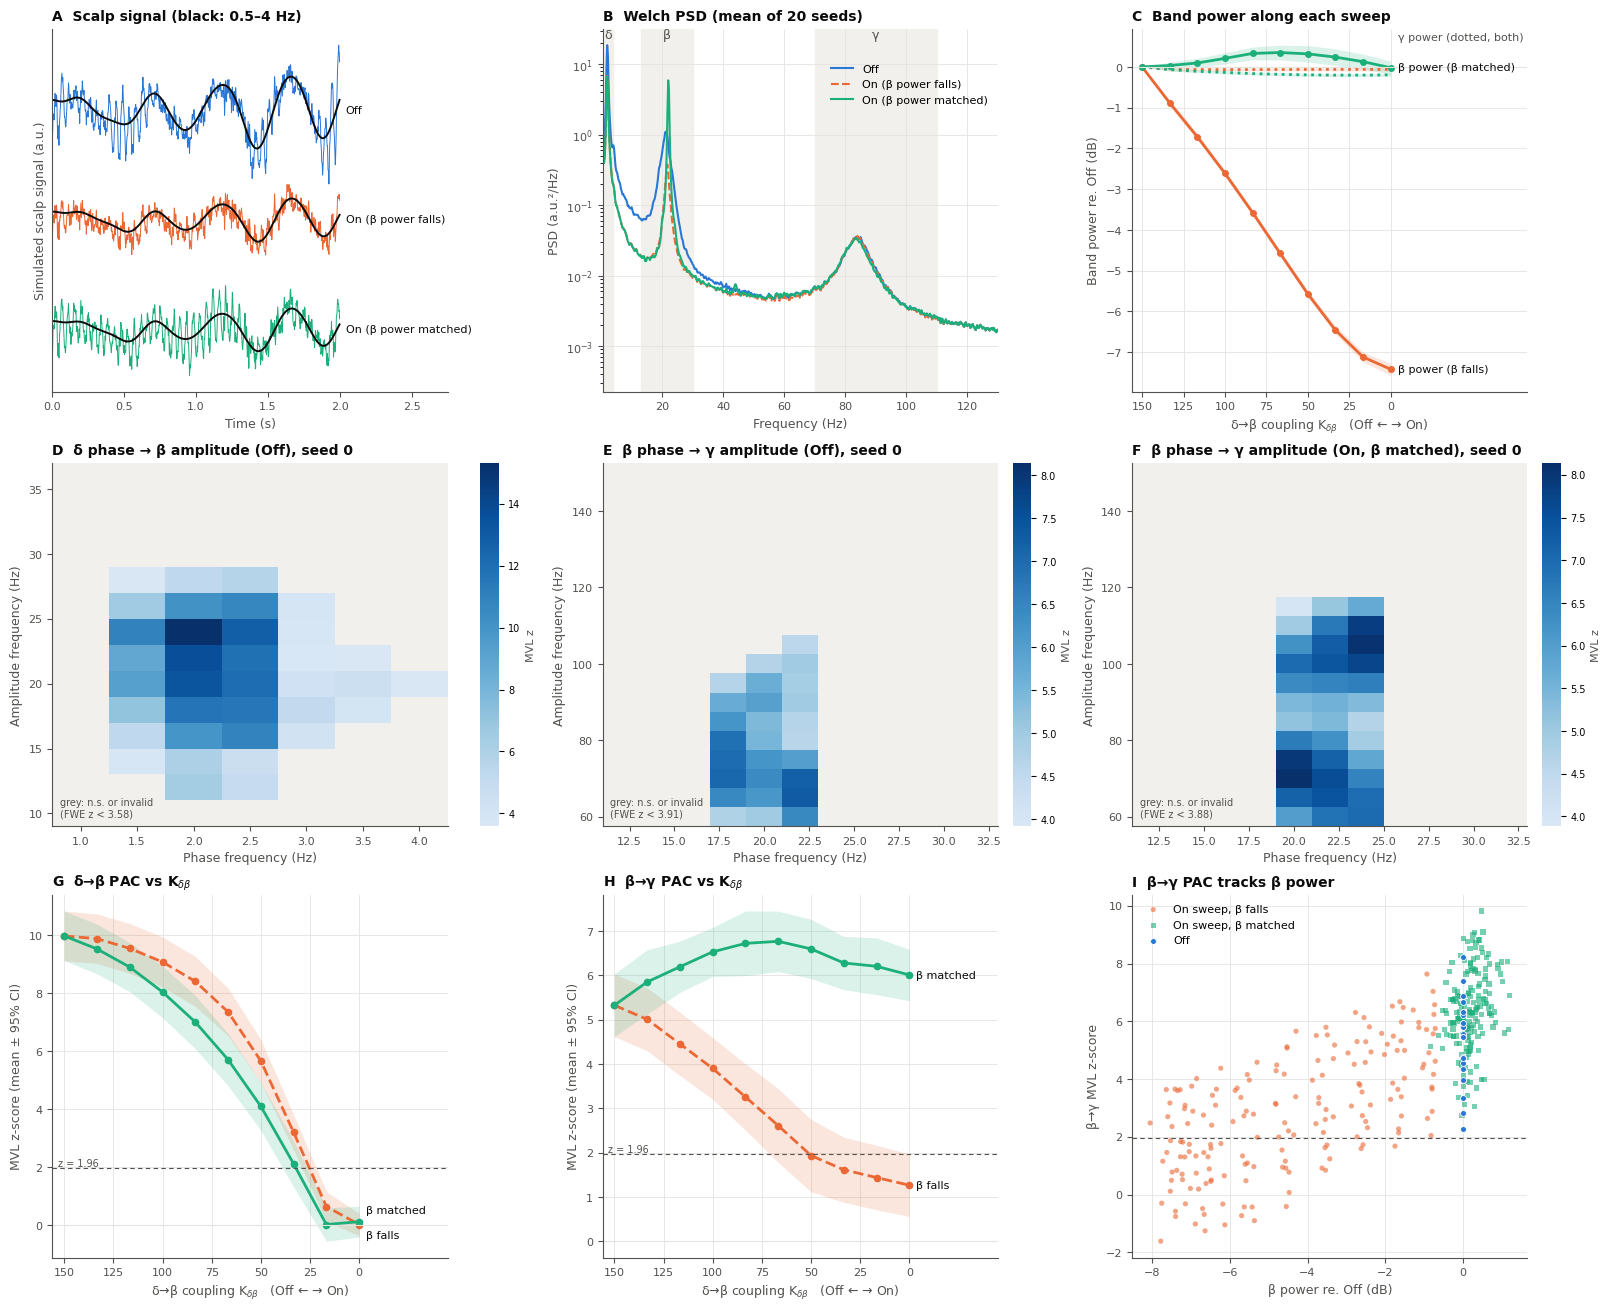

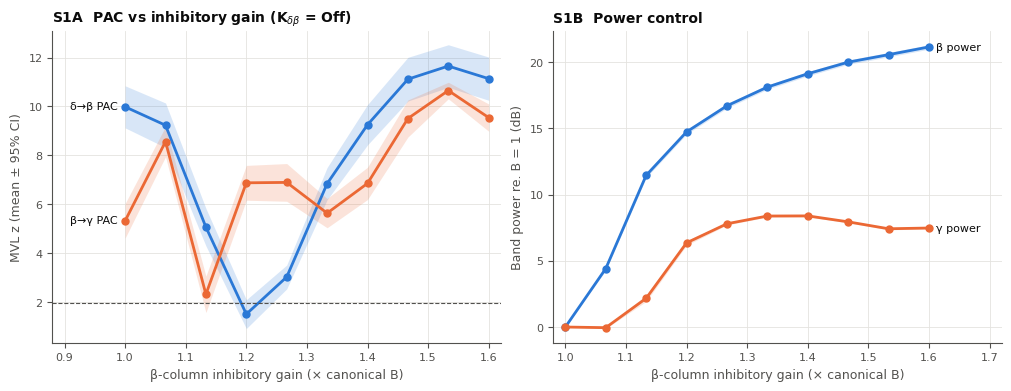

In [8]:
if __name__ == "__main__":
    results = main(CONFIG)

## 7. One-factor sensitivity analysis

Every operating point was hand-tuned near a bifurcation, so the key question is whether the
*sign* of each effect survives small parameter changes. Each parameter is moved ±10 % on its own;
Off, On (β falls) and On (β matched; μ_β re-calibrated for that configuration) are re-simulated with
common random numbers. Figure S2 shows the paired Off − On differences in MVL z.

Sensitivity analysis: each of 6 parameters ±10%, 10 seeds × 30 s, K_on = 33.3
   13 configurations: calibrating power-matched μ_β for each…
   matching β power: 13 case(s) × 6 μ_β values × 4 seeds
  simulating 364 runs: 100.0%  (   25 s elapsed, ~   0 s left)
   simulating 390 runs × 32 s…
  simulating 390 runs: 100.0%  (   38 s elapsed, ~   0 s left)

--------------------------------------------------------------------------------------------------------
   configuration | z δβ Off | z βγ Off |  Δz δβ falls |  Δz βγ falls |  Δz δβ match |  Δz βγ match | Δβ match
--------------------------------------------------------------------------------------------------------
        baseline |     7.51 |     3.40 |    5.63±1.13 |    2.14±0.66 |    6.24±1.22 |   -0.34±1.06 | -0.38 dB
       mu_b −10% |     6.74 |     4.24 |    5.46±1.31 |    1.90±1.09 |    5.55±1.23 |    0.19±1.55 | -0.37 dB
       mu_b +10% |     8.27 |     3.09 |    5.97±1.03 |    2.30±0.85 |    7.00±1.57 |   -0.24±0.75 | -0.1

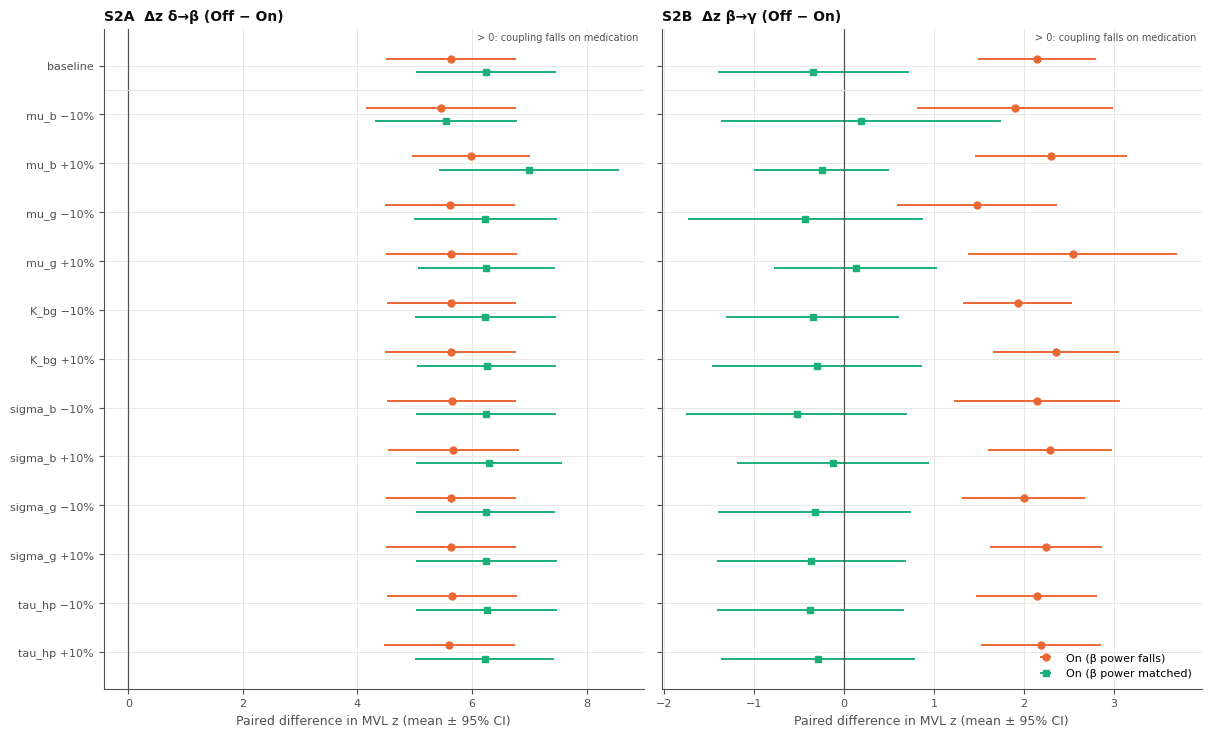

In [9]:
if __name__ == "__main__" and RUN_SENSITIVITY:
    sens_rows = sensitivity(results, CONFIG)

## 8. Two-hit condition: medication also weakens the β→γ interaction

With β power held at the Off level, reducing δ→β coupling alone does not reduce β→γ PAC (section 6).
The patient EEG, however, shows both couplings falling with < 1 dB change in β power. This section
asks whether a **second, independent medication effect on the β→γ interaction** reproduces that
pattern. The β→γ gain is scaled to K_βγ × s, for s = 1.0 … 0.0, in a 2 × 6 factorial design (common
random numbers throughout):

* **β→γ hit only:** K_δβ = Off, K_βγ × s.
* **Two-hit:** K_δβ = On, μ_β at its power-matched value (β power ≈ Off), K_βγ × s.

At s = 1.0 the two conditions are the Off state and the power-matched On state of section 6. The
interaction contrast z(two-hit, s) − z(two-hit, 1) − z(hit 2 only, s) + z(Off) tests whether the two
hits combine additively (≈ 0) or interact.

Reducing K_βγ lowers β→γ PAC almost by construction. The informative outputs are therefore
(i) how large the second hit must be, (ii) whether it leaves δ→β PAC, β power and γ power unchanged,
and (iii) whether the two hits interact.

In [10]:
def run_two_hit(results: dict, cfg: dict = CONFIG, verbose: bool = True) -> dict:
    """Simulate the 2 × len(two_hit_bg_scales) factorial and return metrics and summary arrays."""
    t0 = time.time()
    scales = np.asarray(cfg["two_hit_bg_scales"], float)
    nS, ns = len(scales), cfg["n_seeds"]
    K_off, K_on = cfg["K_db_off"], results["K_on"]
    mu_on = float(results["mu_star"][results["i_on"]])
    S_ref, init_state = results["S_ref_delta"], results["init_state"]
    T = cfg["burn_in"] + cfg["duration"]

    def simulate(mu_two_hit):
        """One batch: hit-2-only sweep, then two-hit sweep (μ_β per scale)."""
        p_a = make_params(cfg, nS * ns, K_db=K_off, K_bg=np.repeat(scales * cfg["K_bg"], ns))
        p_b = make_params(cfg, nS * ns, K_db=K_on, mu_b=np.repeat(mu_two_hit, ns),
                          K_bg=np.repeat(scales * cfg["K_bg"], ns))
        seeds = np.tile(np.arange(ns), 2 * nS)
        if verbose:
            print(f"   simulating {len(seeds)} runs × {T:.0f} s…")
        scalp, _, _ = simulate_network(cfg, concat_params(p_a, p_b), seeds, ns, T, S_ref,
                                       init_state=init_state, verbose=verbose)
        x = to_eeg_rate(scalp, cfg)
        ref = np.zeros(len(seeds), bool); ref[:ns] = True          # Off = hit-2-only at s = 1
        x = add_background(x, seeds, ref, cfg)
        half = nS * ns
        return analyse_batch(x[:half], cfg), analyse_batch(x[half:], cfg)

    def rel_db(m, key, ref):
        v = getattr(m, key).reshape(nS, ns)
        return 10 * np.log10(v / ref[None, :])

    print(f"Two-hit factorial: K_βγ × [{', '.join(f'{v:.1f}' for v in scales)}], K_δβ On = {K_on:.1f}, "
          f"μ_β(On, matched) = {mu_on:.1f}")
    mu_two = np.full(nS, mu_on)
    m_a, m_b = simulate(mu_two)
    off_beta = m_a.pow_beta[:ns]
    drift = rel_db(m_b, "pow_beta", off_beta).mean(1)
    if np.any(np.abs(drift) > cfg["two_hit_rematch_db"]):
        # the gamma column's beta-frequency response also reaches the electrode, so cutting K_βγ can
        # shift scalp β power; re-calibrate μ_β per scale so the two-hit sweep stays power-matched
        print(f"   two-hit β power drifted ({drift.min():.2f} to {drift.max():.2f} dB); re-matching μ_β…")
        cases = [{"case": {"K_db": K_on, "K_bg": s * cfg["K_bg"]}, "ref": {"K_db": K_off}} for s in scales]
        mu_two = match_beta_power(cfg, cases, S_ref, init_state, cfg["match_seeds"], cfg["match_T"],
                                  verbose=verbose)
        m_a, m_b = simulate(mu_two)
        off_beta = m_a.pow_beta[:ns]

    off_gamma = m_a.pow_gamma[:ns]
    out = {"scales": scales, "mu_two_hit": mu_two, "metrics_hit2": m_a, "metrics_two_hit": m_b}
    for tag, m in (("hit2", m_a), ("two", m_b)):
        out[f"zdb_{tag}"] = m.z_db.reshape(nS, ns)
        out[f"zbg_{tag}"] = m.z_bg.reshape(nS, ns)
        out[f"dbeta_{tag}"] = rel_db(m, "pow_beta", off_beta)
        out[f"dgamma_{tag}"] = rel_db(m, "pow_gamma", off_gamma)

    # --- tables ------------------------------------------------------------------------
    off_db, off_bg = out["zdb_hit2"][0], out["zbg_hit2"][0]
    print("\n" + "-" * 112)
    print(f"{'K_βγ ×':>7} | {'condition':>13} | {'z δ→β':>13} | {'z β→γ':>13} | {'Δz δβ (Off−)':>13} | "
          f"{'Δz βγ (Off−)':>13} | {'β power':>8} | {'γ power':>8}")
    print("-" * 112)
    for i, s in enumerate(scales):
        for tag, name in (("hit2", "β→γ hit only"), ("two", "two-hit")):
            zdb, zbg = out[f"zdb_{tag}"][i], out[f"zbg_{tag}"][i]
            if tag == "hit2" and i == 0:
                name = "Off"
            mdb, cdb = mean_ci95(zdb); mbg, cbg = mean_ci95(zbg)
            if tag == "hit2" and i == 0:                     # the Off reference itself
                dd = dg = "—"
            else:
                ddb = paired_effect(off_db, zdb); dbg = paired_effect(off_bg, zbg)
                dd, dg = f"{ddb[0]:5.2f}±{ddb[1]:4.2f}", f"{dbg[0]:5.2f}±{dbg[1]:4.2f}"
            print(f"{s:7.1f} | {name:>13} | {mdb:5.2f} ± {cdb:4.2f} | {mbg:5.2f} ± {cbg:4.2f} | {dd:>13} | "
                  f"{dg:>13} | {out[f'dbeta_{tag}'][i].mean():5.2f} dB | {out[f'dgamma_{tag}'][i].mean():5.2f} dB")
    print("-" * 112)

    print("\nInteraction contrast  z(two-hit, s) − z(two-hit, 1) − z(hit 2 only, s) + z(Off)   (≈ 0: additive)")
    for i, s in enumerate(scales[1:], start=1):
        parts = []
        for key, lab in (("zdb", "δ→β"), ("zbg", "β→γ")):
            inter = out[f"{key}_two"][i] - out[f"{key}_two"][0] - out[f"{key}_hit2"][i] + out[f"{key}_hit2"][0]
            mu, ci = mean_ci95(inter)
            parts.append(f"{lab}: {mu:5.2f} ± {ci:4.2f}")
        print(f"  K_βγ × {s:.1f}:   " + "   ".join(parts))

    # smallest second hit that reproduces the patient pattern
    print("\nPatient pattern = δ→β falls, β→γ falls, |Δβ power| < 1 dB (two-hit condition):")
    found = None
    for i, s in enumerate(scales):
        ddb = paired_effect(off_db, out["zdb_two"][i]); dbg = paired_effect(off_bg, out["zbg_two"][i])
        ok = (ddb[0] - ddb[1] > 0) and (dbg[0] - dbg[1] > 0) and abs(out["dbeta_two"][i].mean()) < 1.0
        print(f"  K_βγ × {s:.1f}: δ→β falls {'yes' if ddb[0] - ddb[1] > 0 else 'no '} | "
              f"β→γ falls {'yes' if dbg[0] - dbg[1] > 0 else 'no '} (d_z = {dbg[2]:5.2f}) | "
              f"Δβ = {out['dbeta_two'][i].mean():5.2f} dB  → {'REPRODUCES' if ok else '—'}")
        if ok and found is None:
            found = s
    if found is None:
        print("  No tested K_βγ reduction reproduces the full pattern.")
    else:
        print(f"  Smallest second hit that reproduces it: K_βγ reduced to {found:.1f} × baseline "
              f"({100 * (1 - found):.0f} % reduction).")
    out["first_reproducing_scale"] = found

    make_two_hit_figure(out).savefig("figure_S3_two_hit.png", dpi=300)
    print(f"Saved figure_S3_two_hit.png ({time.time() - t0:.0f} s).")
    plt.show()
    return out


def make_two_hit_figure(out: dict):
    """S3: PAC and band power vs the size of the β→γ hit, for hit-2-only and two-hit conditions."""
    s = out["scales"]
    fig, axs = plt.subplots(1, 3, figsize=(15, 4.4), constrained_layout=True)
    conds = (("hit2", COL["off"], "o", "--", "β→γ hit only (K$_{δβ}$ Off)"),
             ("two", COL["match"], "s", "-", "Two-hit (K$_{δβ}$ On, β matched)"))
    for ax, key, title in ((axs[0], "zdb", "S3A  δ→β PAC"), (axs[1], "zbg", "S3B  β→γ PAC")):
        for tag, c, mk, ls, lab in conds:
            mu, ci = mean_ci95(out[f"{key}_{tag}"], 1)
            ax.fill_between(s, mu - ci, mu + ci, color=c, alpha=0.16, lw=0)
            ax.plot(s, mu, color=c, marker=mk, ls=ls, lw=2, ms=5, label=lab)
        ax.axhline(mean_ci95(out[f"{key}_hit2"], 1)[0][0], color=COL["ink2"], lw=0.8, ls=":")
        ax.text(s[0], mean_ci95(out[f"{key}_hit2"], 1)[0][0], " Off level", fontsize=7, color=COL["ink2"],
                va="bottom", ha="left")
        ax.axhline(1.96, color=COL["ink2"], lw=0.8, ls=(0, (4, 3)))
        ax.text(s[-1], 1.96, "z = 1.96 ", fontsize=7, color=COL["ink2"], va="bottom", ha="right")
        ax.set_ylabel("MVL z-score (mean ± 95% CI)")
        style_axes(ax, title)
    axs[1].legend(frameon=False, fontsize=8, loc="upper right")
    ax = axs[2]
    for tag, c, mk, ls, lab in conds:
        for key, band_ls, band in (("dbeta", "-", "β"), ("dgamma", ":", "γ")):
            mu, ci = mean_ci95(out[f"{key}_{tag}"], 1)
            ax.fill_between(s, mu - ci, mu + ci, color=c, alpha=0.14, lw=0)
            ax.plot(s, mu, color=c, ls=band_ls, lw=2, marker=mk if band == "β" else None, ms=4.5)
    ax.axhspan(-1, 1, color=COL["band"], zorder=0)
    ax.text(s[-1], 1.0, "±1 dB (patient β change) ", fontsize=7, color=COL["ink2"], ha="right", va="bottom")
    ax.text(0.02, 0.03, "solid: β power   dotted: γ power", transform=ax.transAxes, fontsize=8,
            color=COL["ink2"])
    ax.set_ylabel("Band power re. Off (dB)")
    style_axes(ax, "S3C  Power control")
    for ax in axs:
        ax.set_xlim(s[0] + 0.05, s[-1] - 0.05)          # inverted: no second hit on the left
        ax.set_xlabel("β→γ gain K$_{βγ}$ (× baseline)")
        add_grid(ax)
    return fig

Two-hit factorial: K_βγ × [1.0, 0.8, 0.6, 0.4, 0.2, 0.0], K_δβ On = 33.3, μ_β(On, matched) = 348.6
   simulating 240 runs × 62 s…
  simulating 240 runs: 100.0%  (   61 s elapsed, ~   0 s left)
   two-hit β power drifted (-2.82 to 0.24 dB); re-matching μ_β…
   matching β power: 6 case(s) × 10 μ_β values × 6 seeds
  simulating 396 runs: 100.0%  (   26 s elapsed, ~   0 s left)
   simulating 240 runs × 62 s…
  simulating 240 runs: 100.0%  (   60 s elapsed, ~   0 s left)

----------------------------------------------------------------------------------------------------------------
 K_βγ × |     condition |         z δ→β |         z β→γ |  Δz δβ (Off−) |  Δz βγ (Off−) |  β power |  γ power
----------------------------------------------------------------------------------------------------------------
    1.0 |           Off |  9.99 ± 0.86 |  5.33 ± 0.71 |             — |             — |  0.00 dB |  0.00 dB
    1.0 |       two-hit |  2.11 ± 0.80 |  6.28 ± 0.60 |     7.88±0.91 |    -0.95±0.8

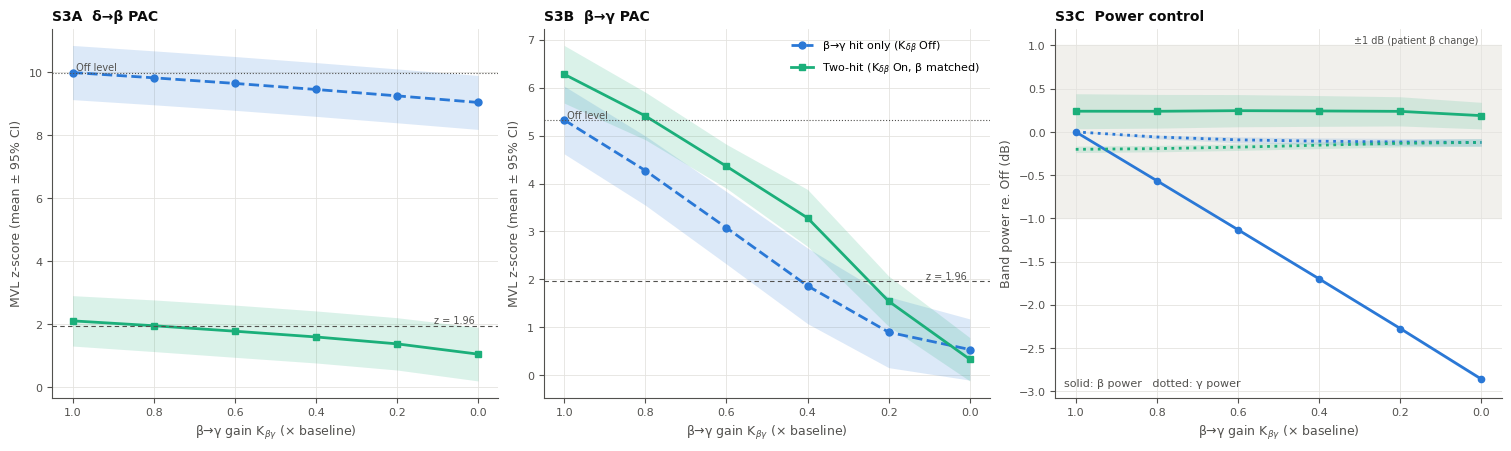

In [11]:
if __name__ == "__main__" and RUN_TWO_HIT:
    two_hit = run_two_hit(results, CONFIG)

## 9. Visualisation gallery

Five alternative views of the same model. Each is built to make one idea visible at a glance:

| Figure | Question it answers |
|---|---|
| **G1 Phase roses** | *Where* in the slow cycle is the fast rhythm strongest, and how does that change on medication? |
| **G2 Nested-oscillation anatomy** | What does δ→β→γ nesting look like in the raw signal? |
| **G3 Phase–phase map** | Is γ amplitude organised by δ phase, β phase, or both (the hierarchy itself)? |
| **G4 Mechanism map** | Across *all* combinations of the two medication effects, where does the patient pattern appear? |
| **G5 Per-seed paired plots** | The model plotted the way patient Off/On data are plotted, one line per "subject". |

The gallery re-simulates what it needs (≈ 5 min on 2 cores), re-using the calibration from section 6.

In [12]:
RUN_GALLERY = True
GALLERY = {
    "n_seeds": 10,
    "duration": 40.0,          # s per condition
    "map_K_steps": 10,         # mechanism map: K_δβ grid (same grid as the main sweep, so it contains K_on)
    "map_bg_scales": (1.0, 0.8, 0.6, 0.4, 0.2, 0.0),
    "map_seeds": 8,
    "map_duration": 40.0,
    "two_hit_scale": 0.4,      # K_βγ scale used for the two-hit example condition
    "n_phase_bins": 18,
    "n_phase_bins_2d": 12,     # coarser grid for the phase–phase map (each cell needs enough samples)
}


def gallery_conditions(results: dict, cfg: dict = CONFIG, g: dict = GALLERY, verbose: bool = True):
    """Simulate Off, On (β falls), On (β matched) and two-hit, sharing noise; return signals and labels."""
    K_off, K_on = cfg["K_db_off"], results["K_on"]
    mu_on = float(results["mu_star"][results["i_on"]])
    S_ref, init_state = results["S_ref_delta"], results["init_state"]
    s2 = g["two_hit_scale"]
    mu_two = match_beta_power(cfg, [{"case": {"K_db": K_on, "K_bg": s2 * cfg["K_bg"]}, "ref": {"K_db": K_off}}],
                              S_ref, init_state, cfg["match_seeds"], cfg["match_T"], verbose=False)[0]
    conds = {"off": {"K_db": K_off},
             "on": {"K_db": K_on},
             "match": {"K_db": K_on, "mu_b": mu_on},
             "two": {"K_db": K_on, "mu_b": mu_two, "K_bg": s2 * cfg["K_bg"]}}
    ns = g["n_seeds"]
    params = concat_params(*[make_params(cfg, ns, **o) for o in conds.values()])
    seeds = np.tile(np.arange(ns), len(conds))
    gcfg = dict(cfg, duration=g["duration"])
    T = cfg["burn_in"] + g["duration"]
    if verbose:
        print(f"   simulating {len(seeds)} runs × {T:.0f} s (4 conditions × {ns} seeds)…")
    scalp, _, _ = simulate_network(gcfg, params, seeds, ns, T, S_ref, init_state=init_state, verbose=verbose)
    x = add_background(to_eeg_rate(scalp, gcfg), seeds, np.arange(len(seeds)) < ns, gcfg)
    return {c: x[i * ns:(i + 1) * ns] for i, c in enumerate(conds)}, gcfg


GLABEL = {"off": "Off", "on": "On · β power falls", "match": "On · β power matched",
          "two": "Two-hit · β matched"}
GCOL = {"off": COL["off"], "on": COL["on"], "match": COL["match"], "two": "#6250d6"}


def phase_profile(x, phase_band, amp_band, cfg, n_bins):
    """Mean amplitude per phase bin, normalised to the mean (1 = no modulation); averaged over rows."""
    ph, am = phase_and_amplitude(x, phase_band, amp_band, cfg)
    idx = np.clip(((ph + np.pi) / (2 * np.pi) * n_bins).astype(int), 0, n_bins - 1)
    prof = np.stack([np.where(idx == b, am, 0).sum(-1) / np.maximum((idx == b).sum(-1), 1)
                     for b in range(n_bins)], -1)
    prof /= prof.mean(-1, keepdims=True)
    return prof.mean(0)


def plot_phase_roses(sig, cfg, g=GALLERY):
    """G1: polar amplitude-by-phase profiles; rows = coupling pair, columns = condition."""
    B, nb = cfg["bands"], g["n_phase_bins"]
    centers = -np.pi + (np.arange(nb) + 0.5) * 2 * np.pi / nb
    pairs = (("δ phase → β amplitude", B["delta"], B["beta"]), ("β phase → γ amplitude", B["beta"], B["gamma"]))
    cols = ("off", "on", "match", "two")
    fig, axs = plt.subplots(2, 4, figsize=(15, 8), subplot_kw={"projection": "polar"}, constrained_layout=True)
    for r, (name, pb, ab) in enumerate(pairs):
        profs = {c: phase_profile(sig[c], pb, ab, cfg, nb) for c in cols}
        dev = max(np.abs(p - 1).max() for p in profs.values())
        lim = (1 - 1.25 * dev, 1 + 1.25 * dev)
        for j, c in enumerate(cols):
            ax = axs[r, j]
            th = np.append(centers, centers[0]); rr = np.append(profs[c], profs[c][0])
            ax.fill_between(np.linspace(0, 2 * np.pi, 200), lim[0], 1, color=COL["band"], zorder=0)
            ax.plot(np.linspace(0, 2 * np.pi, 200), np.ones(200), color=COL["ink2"], lw=0.8, ls=":")
            ax.fill(th, rr, color=GCOL[c], alpha=0.25, zorder=2)
            ax.plot(th, rr, color=GCOL[c], lw=2, zorder=3)
            pk = centers[np.argmax(profs[c])]
            depth = 100 * (profs[c].max() - profs[c].min())
            ax.annotate("", xy=(pk, profs[c].max()), xytext=(pk, lim[0]),
                        arrowprops=dict(arrowstyle="-|>", color=COL["ink"], lw=1.2), zorder=4)
            ax.set_ylim(*lim)
            ax.set_yticklabels([])
            ax.set_xticks(np.deg2rad([0, 90, 180, 270]))
            ax.set_xticklabels(["0", "π/2", "±π\n(trough)", "−π/2"], fontsize=8, color=COL["ink2"])
            ax.grid(color=COL["grid"], lw=0.6)
            ax.spines["polar"].set_color(COL["grid"])
            title = (GLABEL[c] + "\n") if r == 0 else ""
            ax.set_title(f"{title}modulation depth {depth:.1f} %", fontsize=9, color=COL["ink"], pad=10,
                         fontweight="bold" if r == 0 else "normal")
        axs[r, 0].text(-0.32, 0.5, name, transform=axs[r, 0].transAxes, rotation=90, va="center", ha="center",
                       fontsize=10, fontweight="bold", color=COL["ink"])
    fig.suptitle("G1  Phase roses — fast-rhythm amplitude around the slow cycle "
                 f"(mean of {g['n_seeds']} seeds; dotted circle = no modulation; arrow = preferred phase)",
                 fontsize=11, color=COL["ink"], x=0.01, ha="left")
    return fig


def plot_nested_anatomy(sig, cfg, seconds=(10.0, 13.0)):
    """G2: one Off and one On (β matched) excerpt, decomposed into δ phase, β envelope and γ envelope."""
    from matplotlib.collections import LineCollection
    fs, B, order = cfg["fs_eeg"], cfg["bands"], cfg["filter_order"]
    seg = slice(int(seconds[0] * fs), int(seconds[1] * fs))
    t = np.arange(seg.stop - seg.start) / fs
    fig, axs = plt.subplots(3, 2, figsize=(15, 7.5), sharex=True, constrained_layout=True,
                            gridspec_kw={"height_ratios": [1.4, 1, 1]})
    cmap = plt.get_cmap("twilight_shifted")
    for j, c in enumerate(("off", "match")):
        x = sig[c][0]
        xd = bandpass(x, *B["delta"], fs, order)
        ph = np.angle(signal.hilbert(xd))
        xb = bandpass(x, *B["beta"], fs, order); eb = np.abs(signal.hilbert(xb))
        xg = bandpass(x, *B["gamma"], fs, order); eg = np.abs(signal.hilbert(xg))
        xs, phs = x[seg], ph[seg]
        pts = np.column_stack([t, xs]).reshape(-1, 1, 2)
        lc = LineCollection(np.concatenate([pts[:-1], pts[1:]], 1), cmap=cmap, norm=plt.Normalize(-np.pi, np.pi),
                            lw=1.0)
        lc.set_array(phs[:-1]); axs[0, j].add_collection(lc)
        axs[0, j].plot(t, xd[seg], color=COL["ink"], lw=1.6)
        axs[0, j].set_xlim(0, t[-1]); axs[0, j].set_ylim(xs.min() * 1.1, xs.max() * 1.1)
        troughs = np.abs(phs) > 2.6
        for ax in axs[:, j]:
            ax.fill_between(t, 0, 1, where=troughs, transform=ax.get_xaxis_transform(), color=COL["band"],
                            zorder=0, lw=0)
        axs[1, j].plot(t, xb[seg], color=GCOL[c], lw=0.6, alpha=0.6)
        axs[1, j].plot(t, eb[seg], color=COL["ink"], lw=1.4)
        axs[2, j].plot(t, xg[seg], color=GCOL[c], lw=0.5, alpha=0.6)
        axs[2, j].plot(t, eg[seg], color=COL["ink"], lw=1.2)
        lim_b = 1.1 * max(np.abs(bandpass(sig[k][0], *B["beta"], fs, order)[seg]).max() for k in ("off", "match"))
        lim_g = 1.1 * max(np.abs(bandpass(sig[k][0], *B["gamma"], fs, order)[seg]).max() for k in ("off", "match"))
        axs[1, j].set_ylim(-lim_b, lim_b); axs[2, j].set_ylim(-lim_g, lim_g)
        style_axes(axs[0, j], f"{GLABEL[c]}")
        for ax, lab in zip(axs[:, j], ("scalp signal\n(colour = δ phase)", "β 13–30 Hz\n+ envelope",
                                      "γ 70–110 Hz\n+ envelope")):
            if j == 0:
                ax.set_ylabel(lab)
            ax.set_yticks([])
            if ax is not axs[0, j]:
                style_axes(ax, "")
        axs[2, j].set_xlabel("Time (s)")
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(-np.pi, np.pi))
    cb = fig.colorbar(sm, ax=axs[0, :], fraction=0.02, pad=0.01, ticks=[-np.pi, 0, np.pi])
    cb.ax.set_yticklabels(["−π", "0 (peak)", "π"], fontsize=7); cb.set_label("δ phase", fontsize=8)
    cb.outline.set_visible(False)
    fig.suptitle("G2  Nested-oscillation anatomy (seed 0) — grey bands mark δ troughs. "
                 "Off: β arrives in bursts locked to the δ cycle; On (β matched): the same β power, "
                 "spread evenly across the cycle",
                 fontsize=11, color=COL["ink"], x=0.01, ha="left")
    return fig


def plot_phase_phase(sig, cfg, g=GALLERY):
    """G3: γ amplitude as a joint function of δ phase and β phase (percent change from the mean)."""
    B, nb = cfg["bands"], g["n_phase_bins_2d"]
    fig, axs = plt.subplots(1, 4, figsize=(16, 4.6), constrained_layout=True)
    maps = {}
    for c in ("off", "on", "match", "two"):
        x = sig[c]
        phd, _ = phase_and_amplitude(x, B["delta"], B["beta"], cfg)
        phb, amg = phase_and_amplitude(x, B["beta"], B["gamma"], cfg)
        acc = np.zeros((nb, nb))
        for r in range(x.shape[0]):
            s, _, _ = np.histogram2d(phd[r], phb[r], bins=nb, range=[[-np.pi, np.pi]] * 2, weights=amg[r])
            n, _, _ = np.histogram2d(phd[r], phb[r], bins=nb, range=[[-np.pi, np.pi]] * 2)
            m = s / np.maximum(n, 1)
            acc += 100 * (m / amg[r].mean() - 1)
        maps[c] = acc / x.shape[0]
    vmax = max(np.abs(m).max() for m in maps.values())
    edges = np.linspace(-np.pi, np.pi, nb + 1)
    for ax, c in zip(axs, maps):
        mesh = ax.pcolormesh(edges, edges, maps[c].T, cmap="RdBu_r", vmin=-vmax, vmax=vmax, shading="flat")
        ax.set_xticks([-np.pi, 0, np.pi]); ax.set_xticklabels(["−π", "0", "π"])
        ax.set_yticks([-np.pi, 0, np.pi]); ax.set_yticklabels(["−π", "0", "π"])
        ax.set_xlabel("δ phase"); ax.set_aspect("equal")
        rng_ = maps[c].max() - maps[c].min()
        style_axes(ax, f"{GLABEL[c]}\nrange {rng_:.0f} %")
    axs[0].set_ylabel("β phase")
    cb = fig.colorbar(mesh, ax=axs, fraction=0.015, pad=0.01)
    cb.set_label("γ amplitude vs mean (%)", fontsize=8); cb.outline.set_visible(False)
    fig.suptitle(f"G3  Phase–phase map: γ amplitude in each (δ phase, β phase) cell, mean of {g['n_seeds']} seeds. "
                 "Variation across columns = γ follows δ; across rows = γ follows β; "
                 "a localised patch = γ depends on both (nesting)", fontsize=10.5, color=COL["ink"],
                 x=0.01, ha="left")
    return fig


def mechanism_map(results: dict, cfg: dict = CONFIG, g: dict = GALLERY, verbose: bool = True):
    """Simulate a K_δβ × K_βγ grid with β power re-matched to Off in every cell; return the summary grid."""
    K_off = cfg["K_db_off"]
    Ks = np.linspace(K_off, 0.0, g["map_K_steps"])
    Ss = np.asarray(g["map_bg_scales"], float)
    S_ref, init_state = results["S_ref_delta"], results["init_state"]
    cells = [(K, s) for K in Ks for s in Ss]
    if verbose:
        print(f"   mechanism map: {len(Ks)} K_δβ × {len(Ss)} K_βγ cells; re-matching β power in each…")
    mcfg = dict(cfg, match_mu_steps=6)
    cases = [{"case": {"K_db": K, "K_bg": s * cfg["K_bg"]}, "ref": {"K_db": K_off}} for K, s in cells]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        mu = match_beta_power(mcfg, cases, S_ref, init_state, 3, cfg["match_T"], verbose=False)
    mu[[i for i, (K, s) in enumerate(cells) if K == K_off and s == 1.0]] = cfg["beta"]["mu"]
    ns = g["map_seeds"]
    params = concat_params(*[make_params(cfg, ns, K_db=K, K_bg=s * cfg["K_bg"], mu_b=m)
                             for (K, s), m in zip(cells, mu)])
    seeds = np.tile(np.arange(ns), len(cells))
    mc = dict(cfg, duration=g["map_duration"])
    T = cfg["burn_in"] + g["map_duration"]
    if verbose:
        print(f"   simulating {len(seeds)} runs × {T:.0f} s…")
    scalp, _, _ = simulate_network(mc, params, seeds, ns, T, S_ref, init_state=init_state, verbose=verbose)
    off_row = [i for i, (K, s) in enumerate(cells) if K == K_off and s == 1.0][0]
    ref = np.zeros(len(seeds), bool); ref[off_row * ns:(off_row + 1) * ns] = True
    x = add_background(to_eeg_rate(scalp, mc), seeds, ref, mc)
    m = analyse_batch(x, mc)
    shape = (len(Ks), len(Ss), ns)
    zdb, zbg = m.z_db.reshape(shape), m.z_bg.reshape(shape)
    pb = m.pow_beta.reshape(shape)
    i0, j0 = np.unravel_index(off_row, shape[:2])
    out = {"K": Ks, "S": Ss, "zdb": zdb, "zbg": zbg,
           "dbeta": 10 * np.log10(pb / pb[i0, j0][None, None, :])}
    # does each cell reproduce the patient pattern? (paired vs Off, CI excludes 0, |Δβ| < 1 dB)
    rep = np.zeros(shape[:2], bool)
    for i in range(len(Ks)):
        for j in range(len(Ss)):
            a = paired_effect(zdb[i0, j0], zdb[i, j]) if (i, j) != (i0, j0) else (0, 1, 0)
            b = paired_effect(zbg[i0, j0], zbg[i, j]) if (i, j) != (i0, j0) else (0, 1, 0)
            rep[i, j] = (a[0] - a[1] > 0) and (b[0] - b[1] > 0) and abs(out["dbeta"][i, j].mean()) < 1
    out["reproduces"] = rep
    return out


def plot_mechanism_map(mm: dict, results: dict, cfg: dict = CONFIG):
    """G4: β→γ PAC as colour (one tile per simulated cell), δ→β PAC as labelled contours,
    tiles that reproduce the patient pattern outlined and hatched."""
    from matplotlib.patches import Rectangle
    K, S = mm["K"], mm["S"]
    zbg, zdb = mm["zbg"].mean(-1), mm["zdb"].mean(-1)
    dK, dS = abs(K[1] - K[0]), abs(S[1] - S[0])
    fig, ax = plt.subplots(figsize=(10, 6.8), constrained_layout=True)
    cmap = ListedColormap(plt.get_cmap("Blues")(np.linspace(0.08, 1.0, 256)))
    mesh = ax.pcolormesh(K, S, zbg.T, cmap=cmap, shading="nearest", vmin=0, vmax=np.ceil(zbg.max()),
                         edgecolors="white", linewidth=1.5)
    cs = ax.contour(K, S, zdb.T, levels=[2, 4, 6, 8], colors=COL["ink"], linewidths=1.2)
    ax.clabel(cs, fmt=lambda v: f"δ→β z = {v:.0f}", fontsize=8, inline_spacing=4)
    for i, k in enumerate(K):
        for j, s_ in enumerate(S):
            if mm["reproduces"][i, j]:
                ax.add_patch(Rectangle((k - dK / 2, s_ - dS / 2), dK, dS, fill=False, hatch="///",
                                       edgecolor=GCOL["two"], lw=2.4, zorder=4))
            ax.text(k, s_, f"{zbg[i, j]:.1f}", ha="center", va="center", fontsize=7,
                    color="white" if zbg[i, j] > 0.6 * zbg.max() else COL["ink"], zorder=5)
    K_on = results["K_on"]
    for lab, kx, sy, mk in (("Off", cfg["K_db_off"], 1.0, "o"), ("single hit\n(β matched)", K_on, 1.0, "s")):
        ax.scatter([kx], [sy + 0.32 * dS], s=70, marker=mk, color="white", edgecolors=COL["ink"],
                   linewidths=1.5, zorder=6)
        ax.annotate(lab, (kx, sy + 0.32 * dS), xytext=(8, -3), textcoords="offset points", fontsize=8.5,
                    color=COL["ink"], fontweight="bold", va="center", zorder=6)
    ax.set_xlim(K[0] + dK / 2, K[-1] - dK / 2)          # inverted: Off on the left
    ax.set_ylim(S[-1] - dS / 2, S[0] + dS / 2)
    ax.set_xticks(K); ax.set_xticklabels([f"{k:.0f}" for k in K])
    ax.set_yticks(S)
    ax.set_xlabel("δ→β coupling K$_{δβ}$   (Off ← → weaker)")
    ax.set_ylabel("β→γ coupling K$_{βγ}$ (× baseline)")
    cb = fig.colorbar(mesh, ax=ax, fraction=0.04, pad=0.02)
    cb.set_label("β→γ PAC, MVL z (tile colour and number)", fontsize=8.5); cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=8)
    style_axes(ax, "G4  Mechanism map: every combination of the two medication effects, β power matched to Off")
    fig.text(0.01, 0.005, "Black contours: δ→β PAC.  Hatched purple tiles reproduce the patient pattern: both "
             "couplings fall vs Off (95% CI excludes 0) with |Δβ power| < 1 dB.\nEvery tile has μ_β re-fitted so "
             "β power equals Off.  Grid: 8 seeds × 40 s per tile, so the threshold is coarser than in section 8.",
             fontsize=8, color=COL["ink2"], va="bottom", ha="left")
    fig.get_layout_engine().set(rect=(0, 0.06, 1, 0.94))
    return fig


def plot_paired_seeds(sig, cfg, g=GALLERY):
    """G5: per-seed Off→On lines, as one would plot patients (each seed ≈ one 'subject')."""
    shifts = None
    z = {}
    for c in sig:
        m = analyse_batch(sig[c], cfg)
        z[c] = {"z_db": m.z_db, "z_bg": m.z_bg}
    fig, axs = plt.subplots(2, 3, figsize=(13, 7.5), sharey="row", constrained_layout=True)
    for r, (key, lab) in enumerate((("z_db", "δ→β PAC (MVL z)"), ("z_bg", "β→γ PAC (MVL z)"))):
        for j, c in enumerate(("on", "match", "two")):
            ax = axs[r, j]
            a, b = z["off"][key], z[c][key]
            for ya, yb in zip(a, b):
                ax.plot([0, 1], [ya, yb], color=COL["ink2"], lw=0.8, alpha=0.45, zorder=1)
            ax.scatter(np.zeros_like(a), a, s=22, color=GCOL["off"], zorder=2, edgecolors="white", linewidths=0.5)
            ax.scatter(np.ones_like(b), b, s=22, color=GCOL[c], zorder=2, edgecolors="white", linewidths=0.5)
            ax.plot([0, 1], [a.mean(), b.mean()], color=COL["ink"], lw=2.6, zorder=3)
            mu, ci, d = paired_effect(a, b)
            ax.axhline(1.96, color=COL["ink2"], lw=0.8, ls=(0, (4, 3)))
            ax.text(0.5, 0.97, f"Δz = {mu:.1f} ± {ci:.1f}   d$_z$ = {d:.1f}", transform=ax.transAxes,
                    ha="center", va="top", fontsize=8.5, color=COL["ink"])
            ax.set_xlim(-0.35, 1.35); ax.set_xticks([0, 1])
            ax.set_xticklabels(["Off", GLABEL[c].replace(" · ", "\n")], fontsize=8)
            if j == 0:
                ax.set_ylabel(lab)
            add_grid(ax)
            style_axes(ax, "")
    fig.suptitle(f"G5  Per-seed paired view ({g['n_seeds']} noise realisations ≈ 'subjects'; "
                 "thick line = mean) — plot your patients the same way", fontsize=11, color=COL["ink"],
                 x=0.01, ha="left")
    return fig


def run_gallery(results: dict, cfg: dict = CONFIG, g: dict = GALLERY):
    """Simulate what the gallery needs and save figures G1–G5."""
    t0 = time.time()
    print("Gallery: simulating Off / On / On-matched / two-hit…")
    sig, gcfg = gallery_conditions(results, cfg, g)
    figs = {"figure_G1_phase_roses.png": plot_phase_roses(sig, gcfg, g),
            "figure_G2_nested_anatomy.png": plot_nested_anatomy(sig, gcfg),
            "figure_G3_phase_phase.png": plot_phase_phase(sig, gcfg, g),
            "figure_G5_paired_seeds.png": plot_paired_seeds(sig, gcfg, g)}
    print("Gallery: mechanism map…")
    mm = mechanism_map(results, cfg, g)
    figs["figure_G4_mechanism_map.png"] = plot_mechanism_map(mm, results, cfg)
    for name, f in figs.items():
        f.savefig(name, dpi=300)
    print(f"Saved {', '.join(sorted(figs))} ({time.time() - t0:.0f} s).")
    plt.show()
    return {"signals": sig, "mechanism_map": mm}

Gallery: simulating Off / On / On-matched / two-hit…
   simulating 40 runs × 42 s (4 conditions × 10 seeds)…
  simulating 40 runs: 100.0%  (   25 s elapsed, ~   0 s left)
Gallery: mechanism map…
   mechanism map: 10 K_δβ × 6 K_βγ cells; re-matching β power in each…
   simulating 480 runs × 42 s…
  simulating 480 runs: 100.0%  (   56 s elapsed, ~   0 s left)
Saved figure_G1_phase_roses.png, figure_G2_nested_anatomy.png, figure_G3_phase_phase.png, figure_G4_mechanism_map.png, figure_G5_paired_seeds.png (170 s).


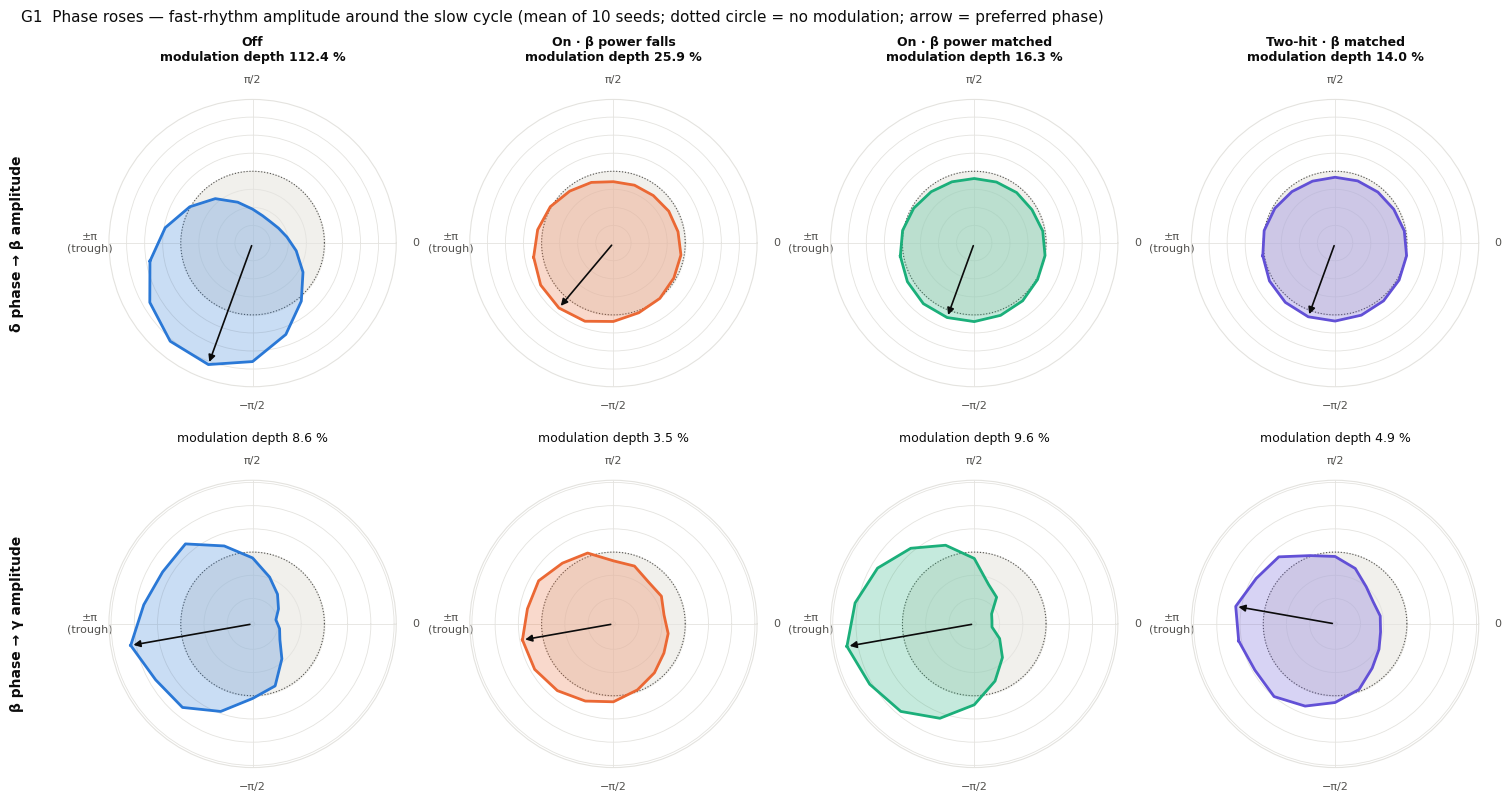

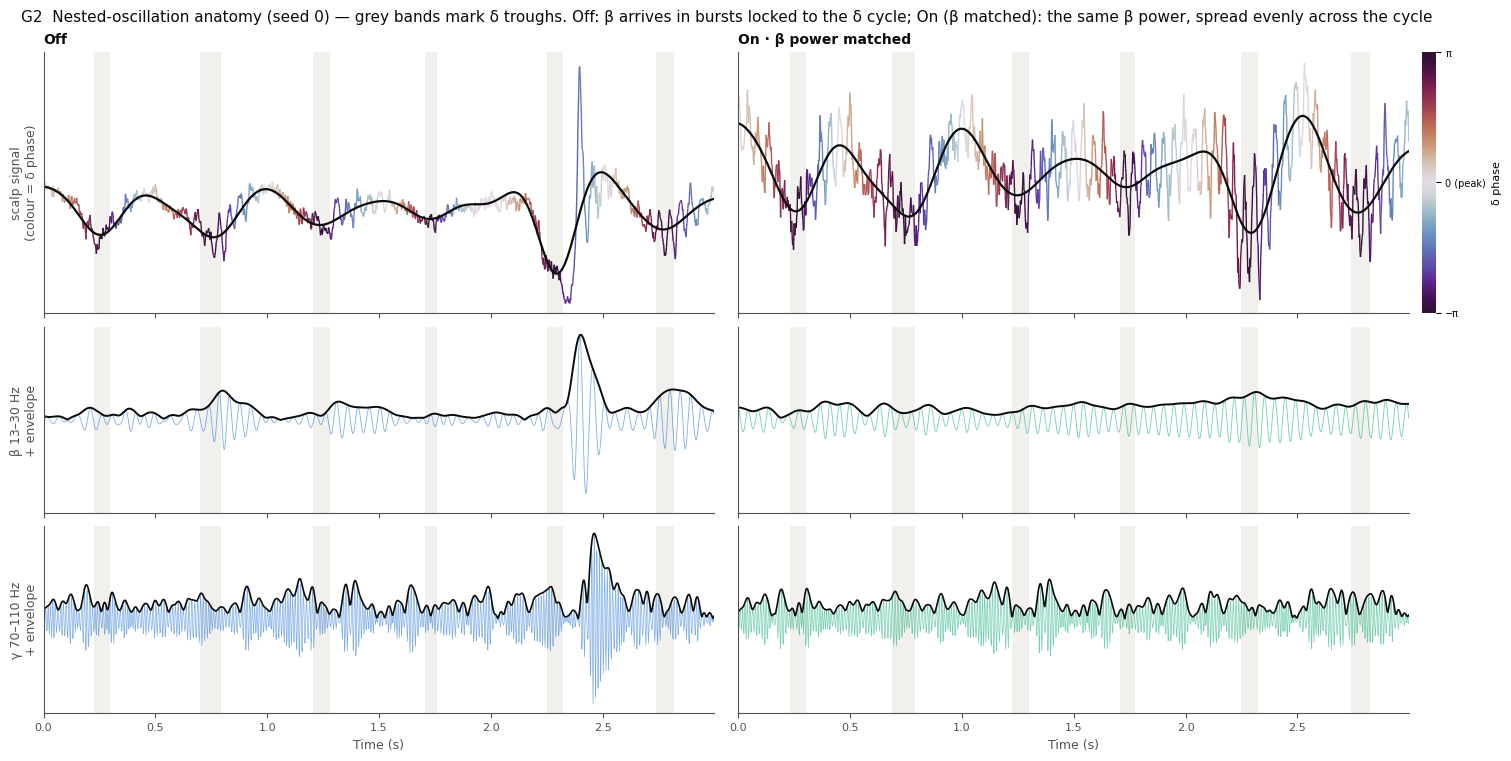

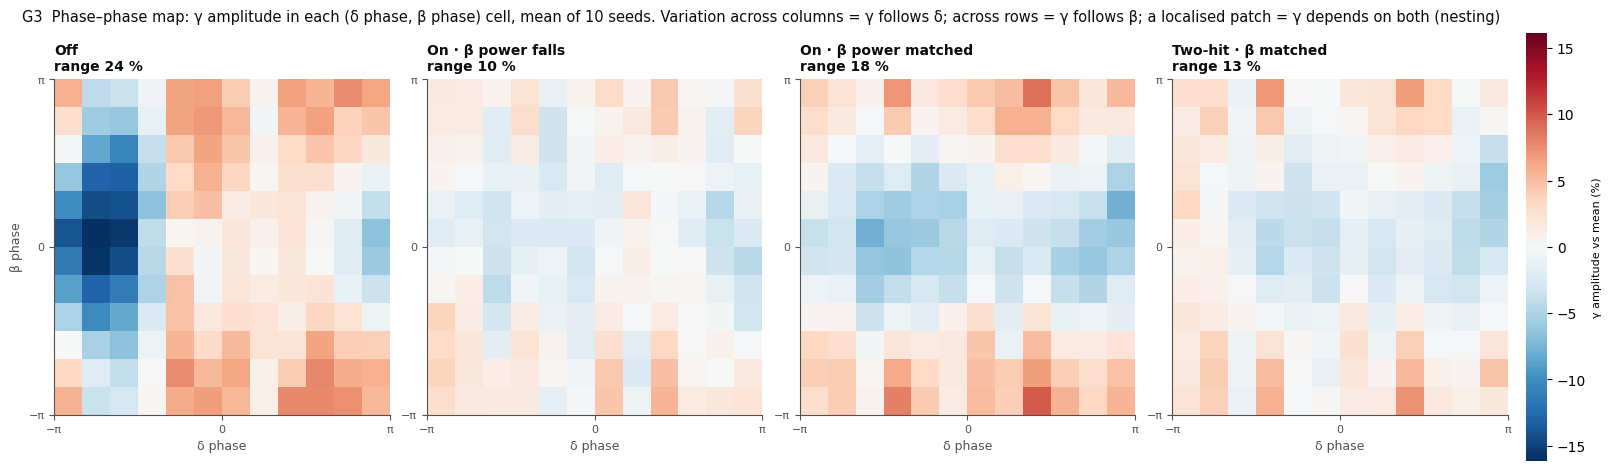

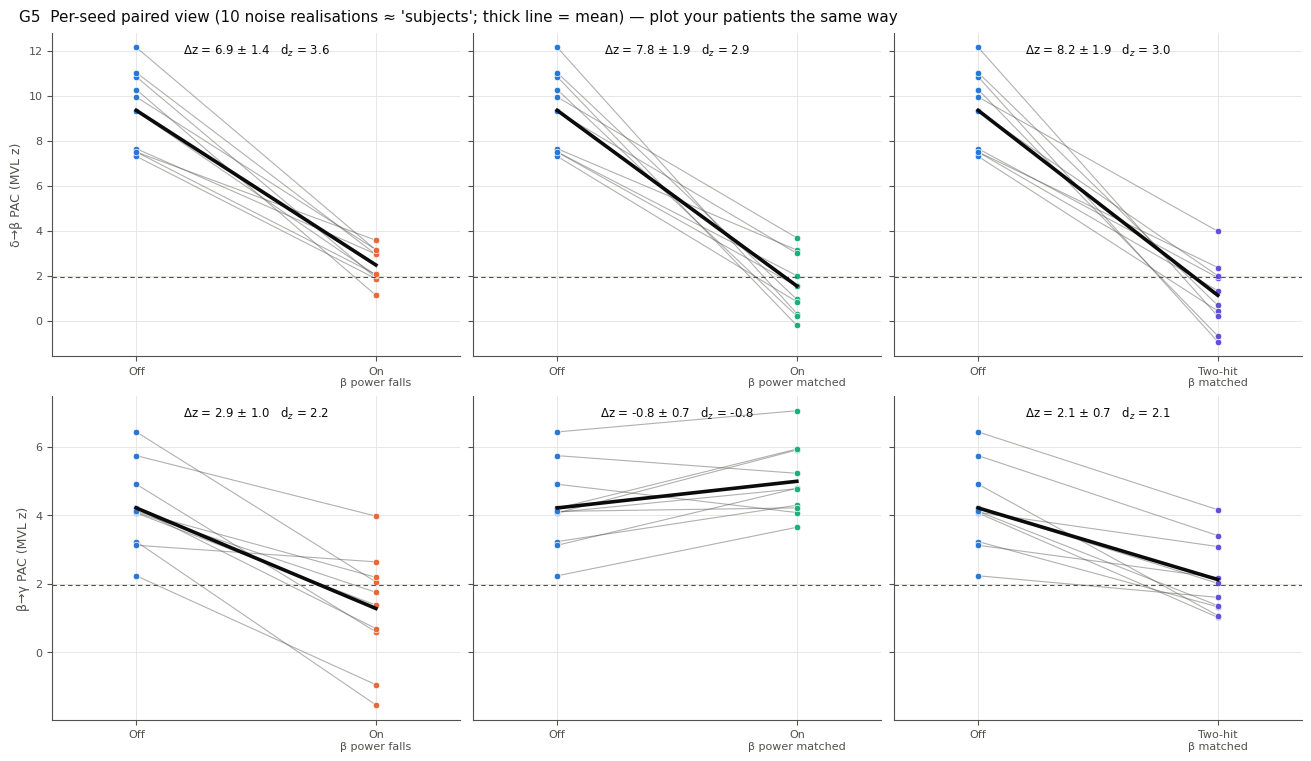

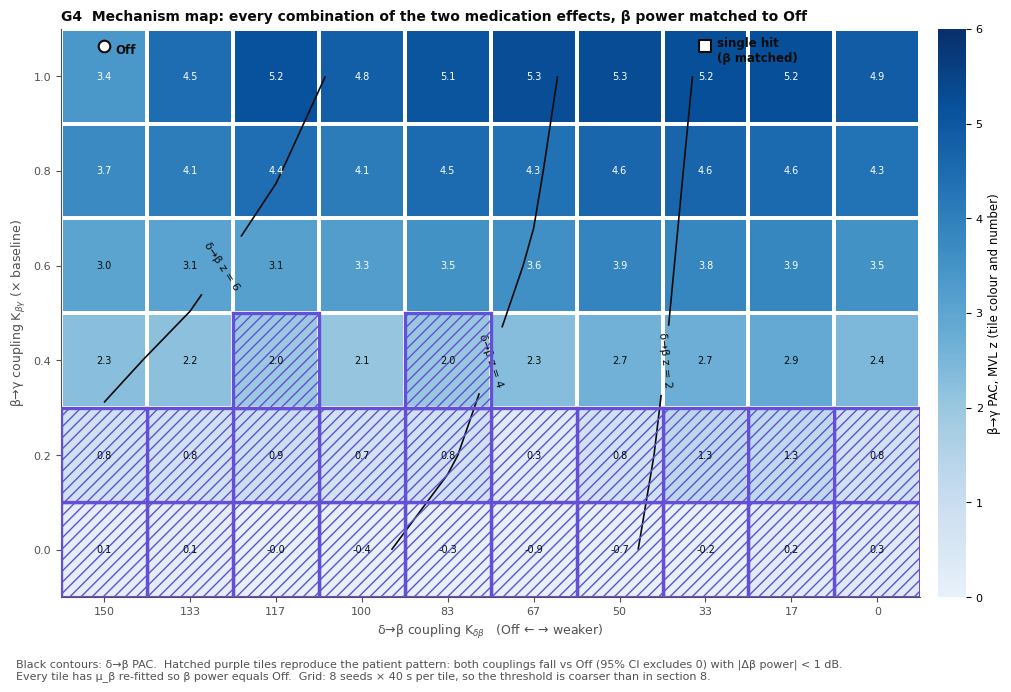

In [13]:
if __name__ == "__main__" and RUN_GALLERY:
    gallery = run_gallery(results, CONFIG)